# FGM Attitudinal Incidence, Women and Men, Kenya, all survey rounds (V2)

Support for continuing FGM, from every Kenya survey that asked about it. Run
`00_EDA_All_Rounds.ipynb` first.

- **Part A — Women** (aged 15–49): DHS 1998, 2008–09, 2014 and 2022 (DHS 2003 did not ask
  the attitude question).
- **Part B — Men** (aged 15–49; men were interviewed up to 54): the DHS men's recodes of 2014
  and 2022 (men were not asked about FGM in 1998 or 2008–09; the 2003 men's file is not
  available), including a design-based comparison with women in the same rounds.
- **Part C — Trends**: bar charts of support for continuation by survey round for women and
  men.

Both parts follow the same steps as V1: predictor screening, collinearity check, design-based
direct estimates, survey-weighted spatial-only and covariate-adjusted BYM2 models by round,
maps, residual patterns, validation and the national trend. Outputs go to
`03_Outputs/KEN/Attitude_Women`, `Attitude_Men` and `Attitude_Women_and_Men`.

# Part A — Women's attitudes

## 0. Configuration

In [1]:
country_name <- "Kenya"
country_iso3 <- "KEN"

project_root <- if (dir.exists("../02_Data")) ".." else "."
analysis_dir <- file.path(project_root, "02_Data", "processed", country_iso3, "analysis")
output_dir <- file.path(project_root, "03_Outputs", country_iso3, "Attitude_Women")
dirs <- list(
  screening = file.path(output_dir, "01_Predictor_Screening"),
  direct = file.path(output_dir, "02_Direct_Estimates"),
  models = file.path(output_dir, "03_Model_Estimates"),
  maps = file.path(output_dir, "04_Maps"),
  trends = file.path(output_dir, "05_Trends"),
  validation = file.path(output_dir, "06_Validation")

)
for (d in dirs) dir.create(d, recursive = TRUE, showWarnings = FALSE)

shapefile_path <- file.path(project_root, "02_Data", "processed", "KEN", "boundaries", "KEN_provinces.shp")
region_var_shapefile <- "PROVINCE"
# Region keys as in the harmonized data: upper case, hyphens as spaces ("CENTRE EST").
standardize_region <- function(x) toupper(as.character(x)) |> stringr::str_replace_all("[^A-Z ]", " ") |> stringr::str_squish()
posterior_draws <- 200L
minimum_cohort_cell_n <- 10L
vif_threshold <- 2
missingness_threshold <- 0.30
round_order <- c("DHS 1998", "DHS 2003", "DHS 2008", "DHS 2014", "DHS 2022")
set.seed(20260918)
options(repr.plot.width = 14, repr.plot.height = 9, width = 200)
cat("Configured for:", country_name, "| outputs:", normalizePath(output_dir, mustWork = FALSE), "\n")

Configured for: Kenya | outputs: /Users/jkakai/Desktop/Main/Melaningod/UNFPA/Root/Working Folder/Final FGM Results/Kenya/V2/03_Outputs/KEN/Attitude_Women 


## 1. Setup

In [2]:
suppressPackageStartupMessages({
  library(tidyverse)
  library(survey)
  library(sf)
  library(spdep)
  library(INLA)
  library(randomForest)
  library(car)
})
options(survey.lonely.psu = "adjust")
theme_set(ggplot2::theme_minimal(base_size = 12))

## 2. Load the attitude data

In [3]:
attitude_all <- readRDS(file.path(analysis_dir, paste0(country_iso3, "_attitude_women.rds"))) |>
  dplyr::mutate(survey_id = factor(survey_id, levels = intersect(round_order, unique(survey_id))))
if (!"birth_cohort" %in% names(attitude_all)) {
  # Men's files give age only; birth year is approximated as survey year minus age.
  attitude_all <- attitude_all |>
    dplyr::mutate(birth_year = round_year - age,
                  birth_cohort = as.character(cut(birth_year, breaks = seq(1950, 2025, by = 5), right = FALSE,
                                                  labels = paste0(seq(1950, 2020, by = 5), " to ", seq(1954, 2024, by = 5)))))
}
survey_years <- attitude_all |> dplyr::distinct(survey_id, survey_type, round_year) |> dplyr::arrange(survey_id)

IRdisplay::display(as.data.frame(attitude_all |> dplyr::group_by(survey_id) |>
  dplyr::summarise(respondents = dplyr::n(), supports_continuation = sum(supports_continuation == 1),
                   supports_stopping = sum(supports_continuation == 0),
                   unweighted_pct_continue = round(100 * mean(supports_continuation), 1), .groups = "drop")))

survey_id,respondents,supports_continuation,supports_stopping,unweighted_pct_continue
<fct>,<int>,<int>,<int>,<dbl>
DHS 1998,7314,1378,0,137800
DHS 2008,7609,1234,0,123400
DHS 2014,14073,1762,0,176200
DHS 2022,15890,1606,0,160600


## 3. Attitude-specific predictor screening

Missingness is checked by round. Random-forest permutation importance is computed on a
pooled sample (up to 3,000 respondents per round) and used only for ranking.
Own FGM status and age are retained a priori; own FGM status is kept if at least half of respondents have it
(0.5 completeness rule), other predictors if at least 70% do.

In [4]:
candidate_predictors <- c("own_status", "age", "education", "wealth", "religion", "ethnicity", "urban_rural", "region")

missingness <- attitude_all |>
  dplyr::group_by(survey_id) |>
  dplyr::summarise(dplyr::across(dplyr::all_of(candidate_predictors), ~ round(mean(is.na(.)), 3)), .groups = "drop")
readr::write_csv(missingness, file.path(dirs$screening, paste0(country_iso3, "_attitude_missingness_by_round.csv")))
IRdisplay::display(as.data.frame(missingness))

# Own FGM status uses a 0.5 completeness rule so a strict threshold cannot drop it in older rounds.
predictor_thresholds <- ifelse(candidate_predictors == "own_status", 0.5, missingness_threshold)
eligible_predictors <- candidate_predictors[colMeans(is.na(attitude_all[candidate_predictors])) < predictor_thresholds]

rf_data <- attitude_all |>
  dplyr::group_by(survey_id) |> dplyr::slice_sample(n = 3000) |> dplyr::ungroup() |>
  dplyr::select(supports_continuation, dplyr::all_of(eligible_predictors)) |>
  tidyr::drop_na() |>
  dplyr::mutate(supports_continuation = factor(supports_continuation),
    own_status = factor(own_status, levels = c(0, 1), labels = c("Not cut", "Cut")),
                dplyr::across(dplyr::where(is.character), as.factor))

rf_model <- randomForest::randomForest(supports_continuation ~ ., data = rf_data, ntree = 500, importance = TRUE)
importance_ranked <- randomForest::importance(rf_model) |> as.data.frame() |>
  tibble::rownames_to_column("variable") |> dplyr::arrange(dplyr::desc(MeanDecreaseAccuracy))
cat("Rows in feature screen:", nrow(rf_data), "\n")
print(importance_ranked)
readr::write_csv(importance_ranked, file.path(dirs$screening, paste0(country_iso3, "_attitude_feature_importance.csv")))

survey_id,own_status,age,education,wealth,religion,ethnicity,urban_rural,region
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
DHS 1998,0.001,0,0,1,0.002,0.001,0,0
DHS 2008,0.000,0,0,0,0.000,0.000,0,0
DHS 2014,0.000,0,0,0,0.000,0.000,0,0
DHS 2022,0.000,0,0,0,0.000,0.000,0,0


Rows in feature screen: 8996 


     variable         0         1 MeanDecreaseAccuracy MeanDecreaseGini
1  own_status 25.971876 44.970434             55.25072        223.24289
2      region 28.867906 30.948381             41.97117        321.53243
3   education  7.567567 38.304943             36.26830        140.11828
4   ethnicity 31.395837 19.914660             33.39797        353.28574
5    religion 24.767871 15.611351             23.94614        147.74618
6         age 21.900606  6.150835             23.34169         99.53613
7 urban_rural 11.497002 15.019528             23.32047         18.70137
8      wealth -1.619022 16.548439             15.01045         63.52555


## 4. Collinearity and final predictor selection

In [5]:
vif_check_model <- stats::glm(stats::reformulate(eligible_predictors, response = "supports_continuation"),
                              data = rf_data, family = stats::binomial())
vif_raw <- car::vif(vif_check_model)
vif_adjusted <- if (is.matrix(vif_raw)) vif_raw[, "GVIF^(1/(2*Df))"] else sqrt(vif_raw)
vif_table <- tibble::tibble(variable = names(vif_adjusted), adjusted_vif = as.numeric(vif_adjusted)) |>
  dplyr::arrange(dplyr::desc(adjusted_vif))
print(vif_table)
vif_flagged <- vif_table$variable[vif_table$adjusted_vif > vif_threshold]
selected_predictors <- unique(c("own_status", "age", setdiff(importance_ranked$variable, vif_flagged)))
selected_predictors <- selected_predictors[selected_predictors %in% eligible_predictors]
cat("Final attitude predictor list:", paste(selected_predictors, collapse = ", "), "\n")
cat("Region is represented by the BYM2 effect rather than a fixed effect.\n")
readr::write_csv(vif_table, file.path(dirs$screening, paste0(country_iso3, "_attitude_vif.csv")))
readr::write_csv(tibble::tibble(variable = selected_predictors),
                 file.path(dirs$screening, paste0(country_iso3, "_attitude_selected_predictors.csv")))

# A tibble: 8 × 2
  variable    adjusted_vif
  <chr>              <dbl>
1 region              1.46
2 own_status          1.44
3 urban_rural         1.40
4 ethnicity           1.35
5 religion            1.25
6 education           1.20
7 wealth              1.15
8 age                 1.08


Final attitude predictor list: own_status, age, region, education, ethnicity, religion, urban_rural, wealth 


Region is represented by the BYM2 effect rather than a fixed effect.


## 5. Mixed-variable association matrix

Absolute Spearman correlation (numeric pairs), bias-corrected Cramér's V (categorical
pairs) and the correlation ratio (mixed pairs), on the pooled screening sample.

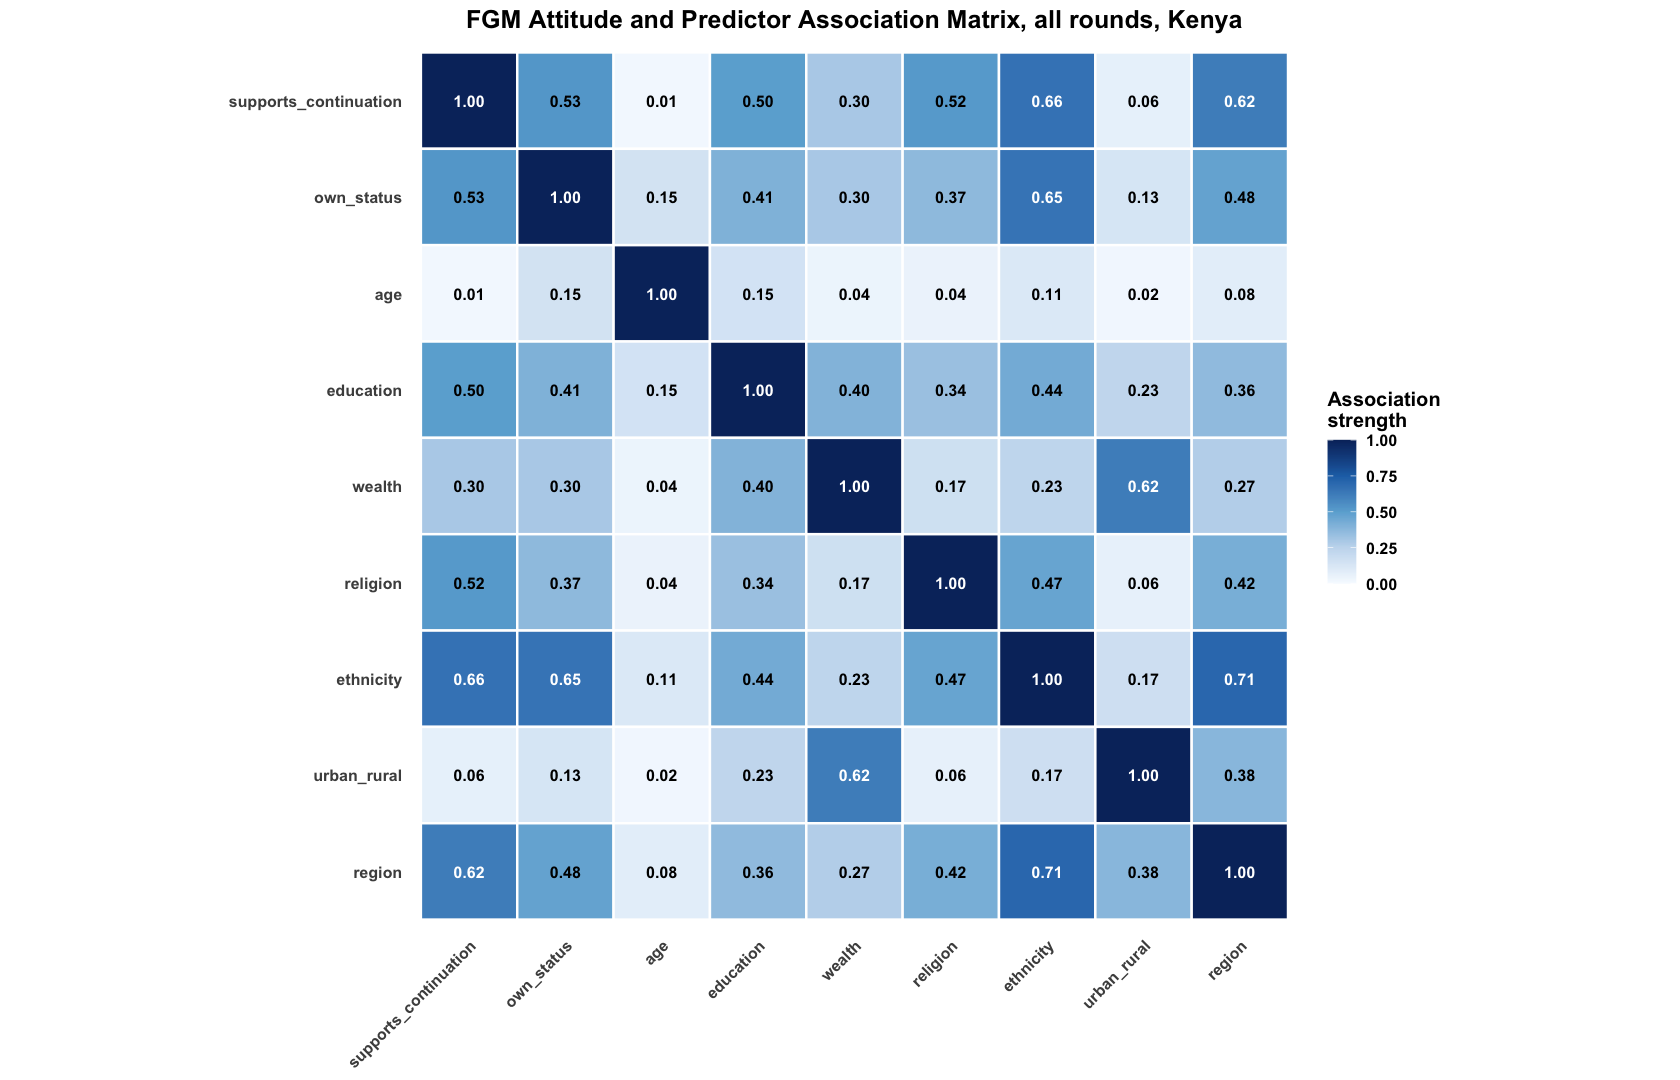

In [6]:
cramers_v_corrected <- function(x, y) {
  keep <- stats::complete.cases(x, y); x <- droplevels(as.factor(x[keep])); y <- droplevels(as.factor(y[keep]))
  if (length(x) == 0L || nlevels(x) < 2L || nlevels(y) < 2L) return(NA_real_)
  tab <- table(x, y); chi2 <- suppressWarnings(as.numeric(stats::chisq.test(tab, correct = FALSE)$statistic))
  n <- sum(tab); r <- nrow(tab); k <- ncol(tab)
  phi2c <- max(0, chi2 / n - ((k - 1) * (r - 1)) / (n - 1))
  den <- min(r - ((r - 1)^2) / (n - 1) - 1, k - ((k - 1)^2) / (n - 1) - 1)
  if (!is.finite(den) || den <= 0) return(NA_real_)
  sqrt(phi2c / den)
}
correlation_ratio <- function(x_numeric, y_category) {
  keep <- stats::complete.cases(x_numeric, y_category)
  x <- as.numeric(x_numeric[keep]); y <- droplevels(as.factor(y_category[keep]))
  if (length(unique(x)) < 2L || nlevels(y) < 2L) return(NA_real_)
  between <- sum(vapply(split(x, y), function(z) length(z) * (mean(z) - mean(x))^2, numeric(1L)))
  sqrt(max(0, min(1, between / sum((x - mean(x))^2))))
}
mixed_association <- function(x, y) {
  if (is.numeric(x) && is.numeric(y)) return(abs(stats::cor(x, y, method = "spearman", use = "complete.obs")))
  if (!is.numeric(x) && !is.numeric(y)) return(cramers_v_corrected(x, y))
  if (is.numeric(x)) correlation_ratio(x, y) else correlation_ratio(y, x)
}
association_data <- rf_data |> dplyr::mutate(supports_continuation = factor(supports_continuation, labels = c("Stop", "Continue")))
association_names <- names(association_data)
association_matrix <- outer(seq_along(association_names), seq_along(association_names), Vectorize(function(i, j)
  if (i == j) 1 else mixed_association(association_data[[i]], association_data[[j]])))
dimnames(association_matrix) <- list(association_names, association_names)
association_long <- as.data.frame(association_matrix) |> tibble::rownames_to_column("variable_y") |>
  tidyr::pivot_longer(-variable_y, names_to = "variable_x", values_to = "association") |>
  dplyr::mutate(variable_x = factor(variable_x, levels = association_names),
                variable_y = factor(variable_y, levels = rev(association_names)))
association_plot <- ggplot2::ggplot(association_long, ggplot2::aes(variable_x, variable_y, fill = association)) +
  ggplot2::geom_tile(color = "white", linewidth = 0.7) +
  ggplot2::geom_text(ggplot2::aes(label = sprintf("%.2f", association), color = association >= 0.55), fontface = "bold", size = 3.4) +
  ggplot2::scale_fill_gradientn(colors = c("#F7FBFF", "#C6DBEF", "#6BAED6", "#2171B5", "#08306B"), limits = c(0, 1),
                                name = "Association\nstrength", na.value = "grey85") +
  ggplot2::scale_color_manual(values = c(`FALSE` = "black", `TRUE` = "white"), guide = "none") +
  ggplot2::coord_fixed() +
  ggplot2::labs(title = paste("FGM Attitude and Predictor Association Matrix, all rounds,", country_name), x = NULL, y = NULL) +
  ggplot2::theme_minimal(base_size = 12) +
  ggplot2::theme(text = ggplot2::element_text(face = "bold"), plot.title = ggplot2::element_text(hjust = 0.5, size = 15),
                 axis.text.x = ggplot2::element_text(angle = 45, hjust = 1), panel.grid = ggplot2::element_blank())
print(association_plot)
ggplot2::ggsave(file.path(dirs$screening, paste0(country_iso3, "_attitude_association_matrix.png")), association_plot,
                width = 10, height = 8, dpi = 300, bg = "white")

## 6. Design-based direct estimates (pooled)

One pooled survey design across all rounds (each survey keeps its own clusters and strata):
pooled estimates by region, and national estimates by survey round for the trend in
section 14. These remain the design-based benchmark.

In [7]:
# Pooled survey-weighted BYM2 model on all survey rounds together. Weights are mean-one
# within each survey, so every round contributes in proportion to its sample size; a
# survey-round term absorbs level differences between rounds. Covariates a round did not
# collect are kept as an "unknown" category so no round is dropped. Respondents with
# identical predictors and outcome are grouped with summed weights, which leaves the
# weighted likelihood unchanged.
prepare_pooled <- function(data, outcome, covariates) {
  data |>
    dplyr::filter(!is.na(.data[[outcome]]), is.finite(weight), weight > 0, is.finite(age),
                  !is.na(birth_cohort), region %in% region_keys) |>
    dplyr::mutate(region_id = match(region, region_keys),
                  dplyr::across(dplyr::all_of(covariates), ~ factor(tidyr::replace_na(as.character(.x), "unknown"))),
                  survey_id = factor(as.character(survey_id)),
                  birth_cohort = as.character(birth_cohort),
                  age_id = as.integer(age - min(age) + 1L)) |>
    dplyr::group_by(dplyr::across(dplyr::all_of(c("region", "region_id", "age_id", "birth_cohort", "survey_id",
                                                  covariates, outcome)))) |>
    dplyr::summarise(survey_weight = sum(weight), n = dplyr::n(), .groups = "drop")
}

fit_pooled <- function(grouped, outcome, covariates, spatial_only = FALSE, n_draws = posterior_draws, seed = 1L) {
  fixed <- if (spatial_only) "1" else paste(c("survey_id", covariates), collapse = " + ")
  age_term <- if (spatial_only) "" else " + f(age_id, model = 'rw2', constr = TRUE, scale.model = TRUE)"
  model_formula <- stats::as.formula(paste0(outcome, " ~ ", fixed, age_term,
    " + f(region_id, model = 'bym2', graph = adjacency_matrix, scale.model = TRUE)"))
  fit <- INLA::inla(model_formula, family = "binomial", data = grouped, Ntrials = rep(1L, nrow(grouped)),
                    weights = grouped$survey_weight,
                    control.predictor = list(compute = TRUE, link = 1),
                    control.compute = list(config = TRUE, dic = TRUE, waic = TRUE),
                    control.inla = list(control.vb = list(enable = FALSE)),
                    # Weakly informative N(0, sd 2) prior on the fixed effects (Kenya): groups with
                    # almost no cases (e.g. Kikuyu girls) otherwise give unbounded coefficients and
                    # inflated, unstable predictions in low-prevalence provinces.
                    control.fixed = list(prec = 0.25, prec.intercept = 0.001))
  set.seed(seed)
  samples <- INLA::inla.posterior.sample(n_draws, fit, use.improved.mean = FALSE, skew.corr = FALSE)
  rows <- grep("^Predictor:", rownames(samples[[1]]$latent))
  rows <- rows[order(as.integer(sub("^Predictor:", "", rownames(samples[[1]]$latent)[rows])))]
  stopifnot(length(rows) == nrow(grouped))
  w <- grouped$survey_weight
  weighted_probs <- lapply(samples, function(s) stats::plogis(as.numeric(s$latent[rows, 1L])) * w)
  rm(samples)
  groupings <- list(
    state = grouped$region,
    state_cohort = paste(grouped$region, grouped$birth_cohort, sep = "|"),
    cohort = grouped$birth_cohort,
    survey = as.character(grouped$survey_id),
    national = rep(country_name, nrow(grouped))
  )
  summaries <- lapply(groupings, function(g) {
    g <- factor(g)
    num <- vapply(weighted_probs, function(pw) as.numeric(rowsum(pw, g)), numeric(nlevels(g)))
    if (is.null(dim(num))) num <- matrix(num, nrow = nlevels(g))
    den <- as.numeric(rowsum(w, g))
    est <- num / den
    tibble::tibble(group = levels(g), estimate = rowMeans(est),
                   lower_ci = apply(est, 1, stats::quantile, 0.025, names = FALSE),
                   upper_ci = apply(est, 1, stats::quantile, 0.975, names = FALSE),
                   n_unweighted = as.numeric(rowsum(grouped$n, g)), sum_weight = den)
  })
  list(fit = fit, state = summaries$state |> dplyr::rename(region = group),
       state_cohort = summaries$state_cohort |> tidyr::separate(group, c("region", "birth_cohort"), sep = "\\|"),
       cohort = summaries$cohort |> dplyr::rename(birth_cohort = group),
       survey = summaries$survey |> dplyr::rename(survey_id = group),
       national = summaries$national |> dplyr::select(-group),
       fixed = tibble::as_tibble(fit$summary.fixed, rownames = "term"),
       residual = tibble::tibble(region = region_keys,
                                 residual_effect = fit$summary.random$region_id$mean[seq_along(region_keys)]),
       fit_stats = tibble::tibble(dic = fit$dic$dic, waic = fit$waic$waic, rows = nrow(grouped),
                                  respondents = sum(grouped$n)))
}

# Pooled design-based direct estimate by a grouping variable (each survey keeps its own
# clusters and strata inside the pooled design).
pooled_direct <- function(data, outcome, by) {
  d <- data |> dplyr::filter(!is.na(.data[[outcome]]))
  design <- survey::svydesign(ids = ~cluster, strata = ~strata, weights = ~weight, data = d, nest = TRUE)
  est <- survey::svyby(stats::as.formula(paste0("~", outcome)), stats::as.formula(paste0("~", by)), design, survey::svymean)
  tibble::tibble(!!by := est[[by]], direct = as.numeric(est[[outcome]]), se = as.numeric(est$se)) |>
    dplyr::mutate(lower_ci = pmax(direct - 1.96 * se, 0), upper_ci = pmin(direct + 1.96 * se, 1),
                  n = as.integer(table(d[[by]])[as.character(.data[[by]])]))
}

# One map per estimate set (V1 style) and a faceted birth-cohort map.
state_map <- function(estimates, value_col, title_text, subtitle_text, legend_title, fill_limits) {
  map_data <- boundaries |> dplyr::mutate(region = region_keys) |> dplyr::left_join(estimates, by = "region")
  ggplot2::ggplot(map_data) +
    ggplot2::geom_sf(ggplot2::aes(fill = .data[[value_col]]), color = "grey40", linewidth = 0.15) +
    ggplot2::scale_fill_viridis_c(name = legend_title, option = "magma", direction = -1,
                                  labels = scales::percent_format(accuracy = 1), limits = fill_limits,
                                  oob = scales::squish, na.value = "grey90") +
    ggplot2::coord_sf(datum = sf::st_crs(4326)) +
    ggplot2::labs(title = title_text, subtitle = subtitle_text, x = "Longitude", y = "Latitude") +
    ggplot2::theme_bw(base_size = 12) +
    ggplot2::theme(plot.title = ggplot2::element_text(face = "bold", size = 15, hjust = 0.5),
                   plot.subtitle = ggplot2::element_text(hjust = 0.5, color = "grey30"),
                   panel.border = ggplot2::element_rect(color = "grey40", fill = NA, linewidth = 0.4),
                   axis.text.x = ggplot2::element_text(angle = 45, hjust = 1, size = 8))
}
cohort_map <- function(estimates, value_col, title_text, subtitle_text, legend_title, fill_limits) {
  map_data <- boundaries |> dplyr::mutate(region = region_keys) |>
    dplyr::left_join(estimates, by = "region", relationship = "one-to-many") |> dplyr::filter(!is.na(birth_cohort))
  ggplot2::ggplot() +
    ggplot2::geom_sf(data = boundaries, fill = "grey90", color = "grey60", linewidth = 0.1) +
    ggplot2::geom_sf(data = map_data, ggplot2::aes(fill = .data[[value_col]]), color = "grey40", linewidth = 0.12) +
    ggplot2::facet_wrap(~birth_cohort, ncol = 4) +
    ggplot2::scale_fill_viridis_c(name = legend_title, option = "magma", direction = -1,
                                  labels = scales::percent_format(accuracy = 1), limits = fill_limits, oob = scales::squish) +
    ggplot2::labs(title = title_text, subtitle = subtitle_text, x = NULL, y = NULL) +
    ggplot2::theme_bw(base_size = 12) +
    ggplot2::theme(plot.title = ggplot2::element_text(face = "bold", size = 16, hjust = 0.5),
                   plot.subtitle = ggplot2::element_text(hjust = 0.5, color = "grey30"),
                   strip.text = ggplot2::element_text(face = "bold", size = 10),
                   strip.background = ggplot2::element_rect(fill = "grey90", color = "grey40"),
                   axis.text = ggplot2::element_blank(), axis.ticks = ggplot2::element_blank())
}
residual_map <- function(residuals, title_text, subtitle_text) {
  lim <- max(abs(residuals$residual_effect), na.rm = TRUE)
  ggplot2::ggplot(boundaries |> dplyr::mutate(region = region_keys) |> dplyr::left_join(residuals, by = "region")) +
    ggplot2::geom_sf(ggplot2::aes(fill = residual_effect), color = "grey40", linewidth = 0.15) +
    ggplot2::scale_fill_gradient2(name = "Residual\nlog-odds", low = "#1D4E89", mid = "white", high = "#D9534F",
                                  midpoint = 0, limits = c(-lim, lim)) +
    ggplot2::labs(title = title_text, subtitle = subtitle_text, x = "Longitude", y = "Latitude") +
    ggplot2::theme_bw(base_size = 12) +
    ggplot2::theme(plot.title = ggplot2::element_text(face = "bold", size = 14, hjust = 0.5),
                   plot.subtitle = ggplot2::element_text(hjust = 0.5, color = "grey30"),
                   axis.text.x = ggplot2::element_text(angle = 45, hjust = 1, size = 8))
}

In [8]:
design_for <- function(d) survey::svydesign(ids = ~cluster, strata = ~strata, weights = ~weight, data = d, nest = TRUE)
direct_by_region <- pooled_direct(attitude_all, "supports_continuation", "region") |>
  dplyr::rename(direct_support = direct, direct_se = se, direct_lower = lower_ci, direct_upper = upper_ci)
direct_national <- pooled_direct(attitude_all |> dplyr::mutate(survey_id = as.character(survey_id)), "supports_continuation", "survey_id") |>
  dplyr::rename(estimate = direct) |> dplyr::mutate(method = "Design-based direct")
pooled_national_direct <- survey::svymean(~supports_continuation, design_for(attitude_all))
readr::write_csv(direct_national, file.path(dirs$direct, paste0(country_iso3, "_attitude_direct_national_by_round.csv")))
readr::write_csv(direct_by_region, file.path(dirs$direct, paste0(country_iso3, "_attitude_direct_by_region.csv")))
cat("Pooled national support for continuation:", round(100 * as.numeric(stats::coef(pooled_national_direct)), 1), "%\n")
IRdisplay::display(as.data.frame(direct_national |> dplyr::mutate(dplyr::across(c(estimate, lower_ci, upper_ci), ~ round(100 * .x, 1)))))

Pooled national support for continuation: 8.7 %


survey_id,estimate,se,lower_ci,upper_ci,n,method
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<chr>
DHS 1998,21.3,0.007646543,19.8,22.8,7314,Design-based direct
DHS 2008,10.3,0.009007077,8.5,12.0,7609,Design-based direct
DHS 2014,6.3,0.002937048,5.7,6.9,14073,Design-based direct
DHS 2022,4.4,0.002571431,3.9,4.9,15890,Design-based direct


## 7. Region boundaries and BYM2 adjacency

In [9]:
boundaries <- sf::st_read(shapefile_path, quiet = TRUE) |> sf::st_make_valid()
region_keys <- standardize_region(boundaries[[region_var_shapefile]])
adjacency <- spdep::poly2nb(boundaries, row.names = region_keys, queen = TRUE)
adjacency_matrix <- spdep::nb2mat(adjacency, style = "B", zero.policy = TRUE)
stopifnot(all(unique(attitude_all$region) %in% region_keys))
cat("Boundary regions:", nrow(boundaries), "\n")

Boundary regions: 8 


## 8–10. Survey-weighted spatial models and posterior estimates (pooled)

As in V1, a spatial-only benchmark and a covariate-adjusted model (the selected predictors
as fixed effects, age as RW2, region as BYM2), each fitted once to all rounds with
normalized survey weights; the adjusted model also has a survey-round term. Predictors a
round did not collect are kept as an "unknown" category. For each posterior draw, fitted
probabilities are averaged with the survey weights within region, region × birth cohort,
survey round and nationally. Intervals are pseudo-posterior.

In [10]:
fixed_covariates <- setdiff(selected_predictors, c("region", "age"))
model_input <- attitude_all
if ("own_status" %in% names(model_input)) {
  model_input <- model_input |>
    dplyr::mutate(own_status = dplyr::case_when(own_status == 1 ~ "Cut", own_status == 0 ~ "Not cut", TRUE ~ NA_character_))
}
grouped <- prepare_pooled(model_input, "supports_continuation", fixed_covariates)
t0 <- Sys.time()
spatial_model <- fit_pooled(grouped, "supports_continuation", fixed_covariates, spatial_only = TRUE, seed = 20260918L)
adjusted_model <- fit_pooled(grouped, "supports_continuation", fixed_covariates, seed = 20260919L)
cat("Pooled models fitted in", round(as.numeric(difftime(Sys.time(), t0, units = "mins")), 1), "min; fixed effects:",
    paste(c("survey round", fixed_covariates), collapse = ", "), "\n")

adjusted_state <- adjusted_model$state |>
  dplyr::rename(adjusted_support = estimate, adjusted_lower = lower_ci, adjusted_upper = upper_ci) |>
  dplyr::left_join(spatial_model$state |> dplyr::select(region, spatial_only = estimate), by = "region") |>
  dplyr::left_join(direct_by_region, by = "region")
adjusted_cohort <- adjusted_model$state_cohort |> dplyr::filter(n_unweighted >= minimum_cohort_cell_n) |>
  dplyr::rename(adjusted_support = estimate)
national_comparison <- dplyr::bind_rows(
  direct_national |> dplyr::select(survey_id, method, estimate, lower_ci, upper_ci),
  adjusted_model$survey |> dplyr::transmute(survey_id, method = "Covariate-adjusted spatial", estimate, lower_ci, upper_ci),
  spatial_model$survey |> dplyr::transmute(survey_id, method = "Spatial only", estimate, lower_ci, upper_ci))
model_fit_comparison <- dplyr::bind_rows(spatial_model$fit_stats |> dplyr::mutate(model = "Spatial only"),
                                         adjusted_model$fit_stats |> dplyr::mutate(model = "Covariate adjusted"))
readr::write_csv(adjusted_state, file.path(dirs$models, paste0(country_iso3, "_attitude_covariate_adjusted_by_region.csv")))
readr::write_csv(adjusted_cohort, file.path(dirs$models, paste0(country_iso3, "_attitude_covariate_adjusted_by_region_cohort.csv")))
readr::write_csv(national_comparison, file.path(dirs$models, paste0(country_iso3, "_attitude_national_comparison_by_round.csv")))
readr::write_csv(model_fit_comparison, file.path(dirs$models, paste0(country_iso3, "_attitude_model_fit.csv")))
readr::write_csv(adjusted_model$fixed, file.path(dirs$models, paste0(country_iso3, "_attitude_fixed_effects.csv")))
readr::write_csv(adjusted_model$residual, file.path(dirs$models, paste0(country_iso3, "_attitude_residual_spatial_effect.csv")))
IRdisplay::display(as.data.frame(model_fit_comparison))
cat("Pooled national support (model):", round(100 * adjusted_model$national$estimate, 1), "%\n")

Pooled models fitted in 0.3 min; fixed effects: survey round, own_status, education, ethnicity, religion, urban_rural, wealth 


dic,waic,rows,respondents,model
<dbl>,<dbl>,<int>,<int>,<chr>
22551.58,22575.95,25414,44886,Spatial only
16205.28,16281.32,25414,44886,Covariate adjusted


Pooled national support (model): 8.8 %


## 11. Covariate-adjusted attitude maps (pooled)

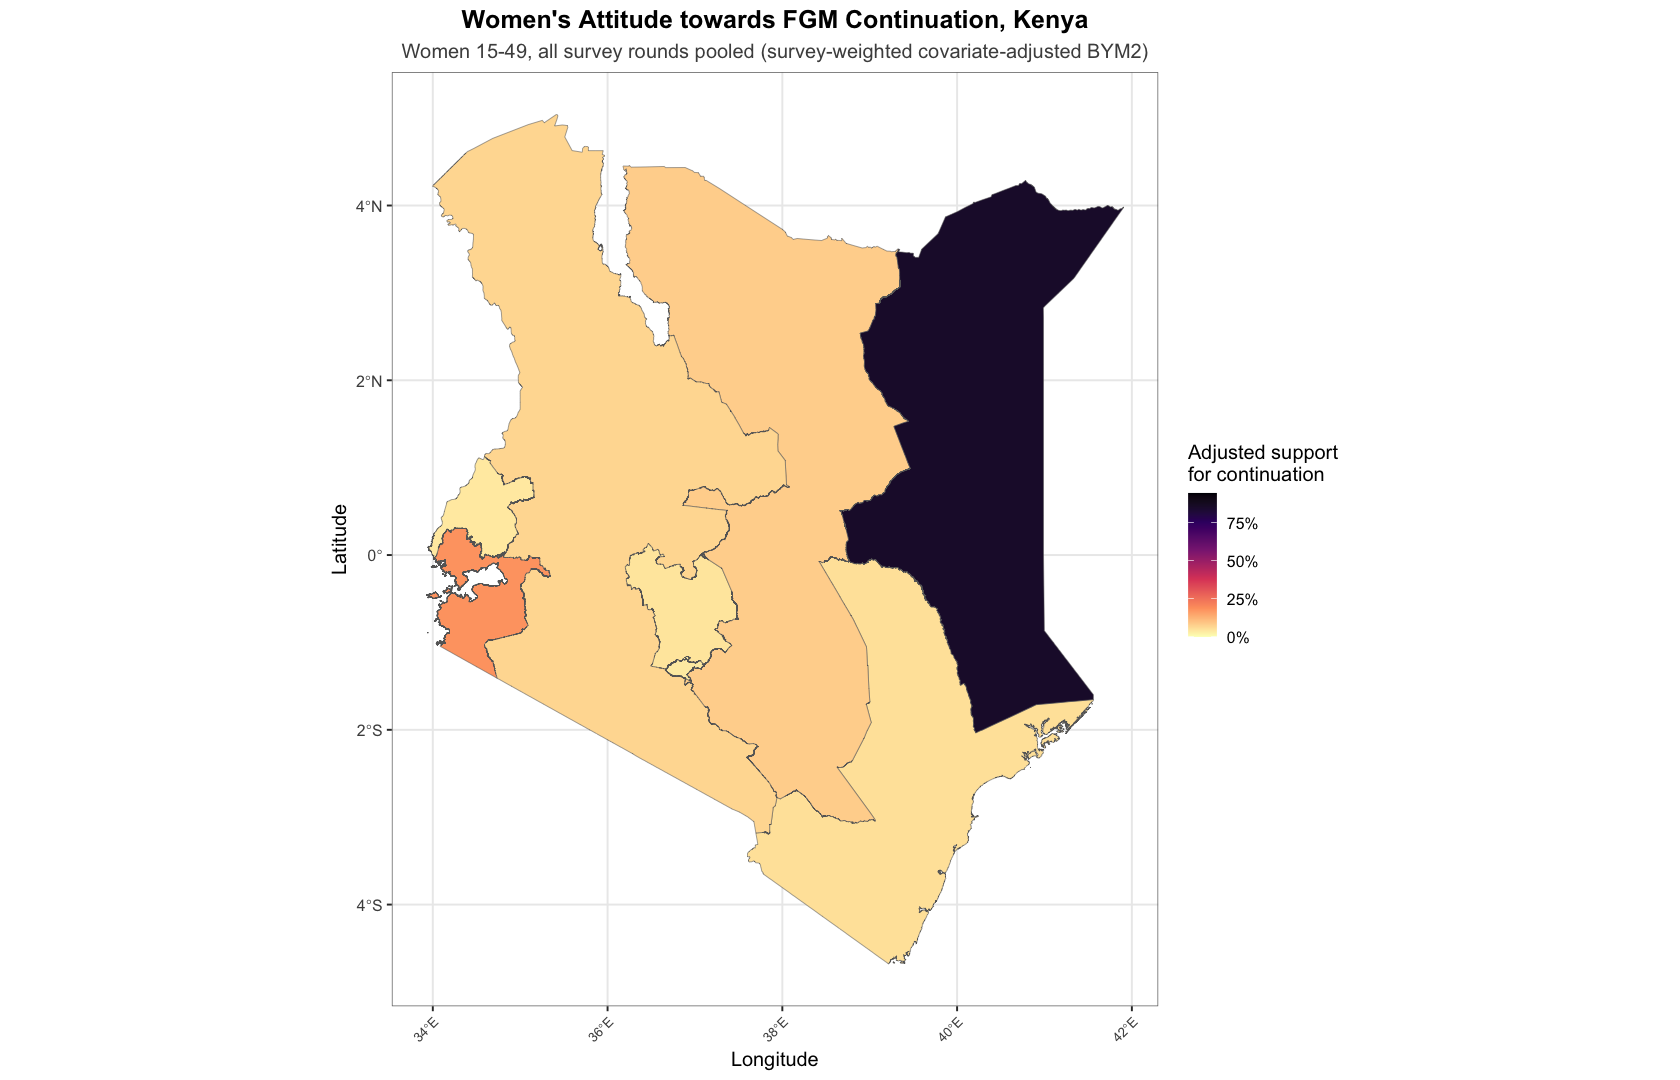

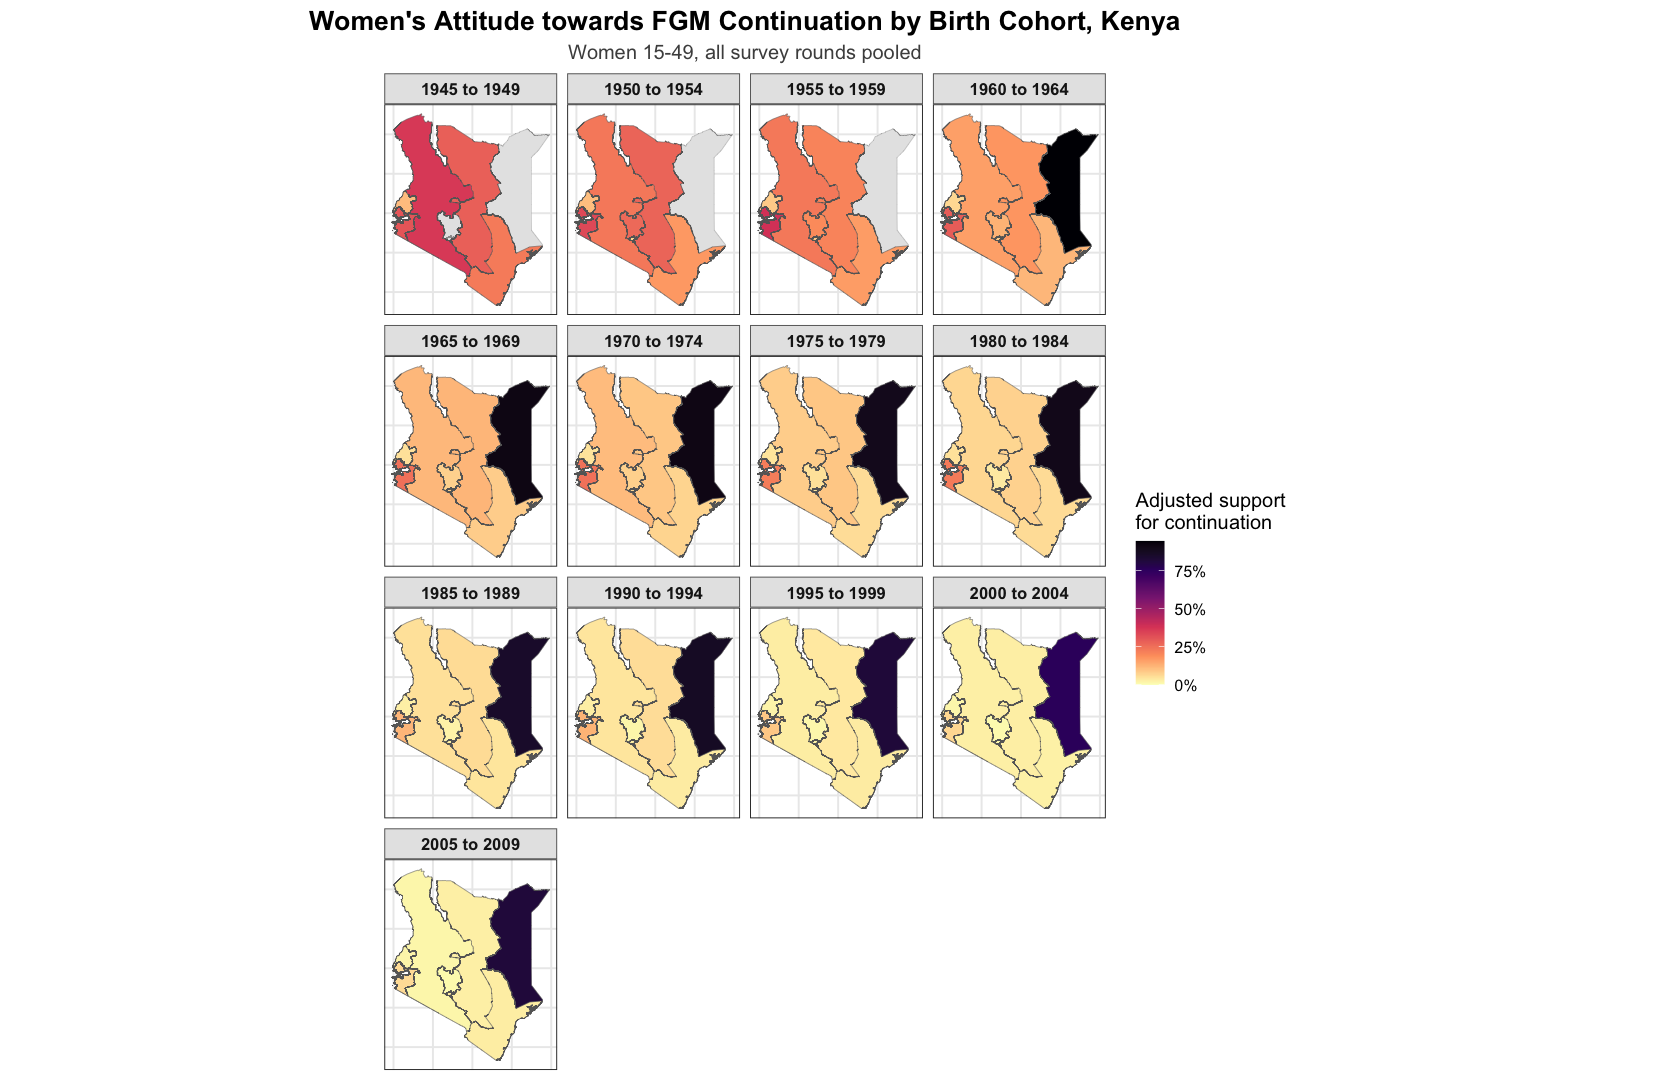

In [11]:
support_fill <- c(0, max(adjusted_state$adjusted_support, adjusted_cohort$adjusted_support))
adjusted_attitude_map <- state_map(adjusted_state, "adjusted_support",
  paste("Women's Attitude towards FGM Continuation,", country_name),
  "Women 15-49, all survey rounds pooled (survey-weighted covariate-adjusted BYM2)", "Adjusted support\nfor continuation", support_fill)
cohort_attitude_map <- cohort_map(adjusted_cohort, "adjusted_support",
  paste("Women's Attitude towards FGM Continuation by Birth Cohort,", country_name),
  "Women 15-49, all survey rounds pooled", "Adjusted support\nfor continuation", support_fill)
print(adjusted_attitude_map); print(cohort_attitude_map)
ggplot2::ggsave(file.path(dirs$maps, paste0(country_iso3, "_attitude_covariate_adjusted_map.png")), adjusted_attitude_map,
                width = 9, height = 8, dpi = 300, bg = "white")
ggplot2::ggsave(file.path(dirs$maps, paste0(country_iso3, "_attitude_covariate_adjusted_map_by_cohort.png")), cohort_attitude_map,
                width = 14, height = 12, dpi = 300, bg = "white")

## 12. Residual geographic pattern (pooled)

The BYM2 effect after adjustment for composition and survey round (relative log-odds, not
an attitude prevalence).

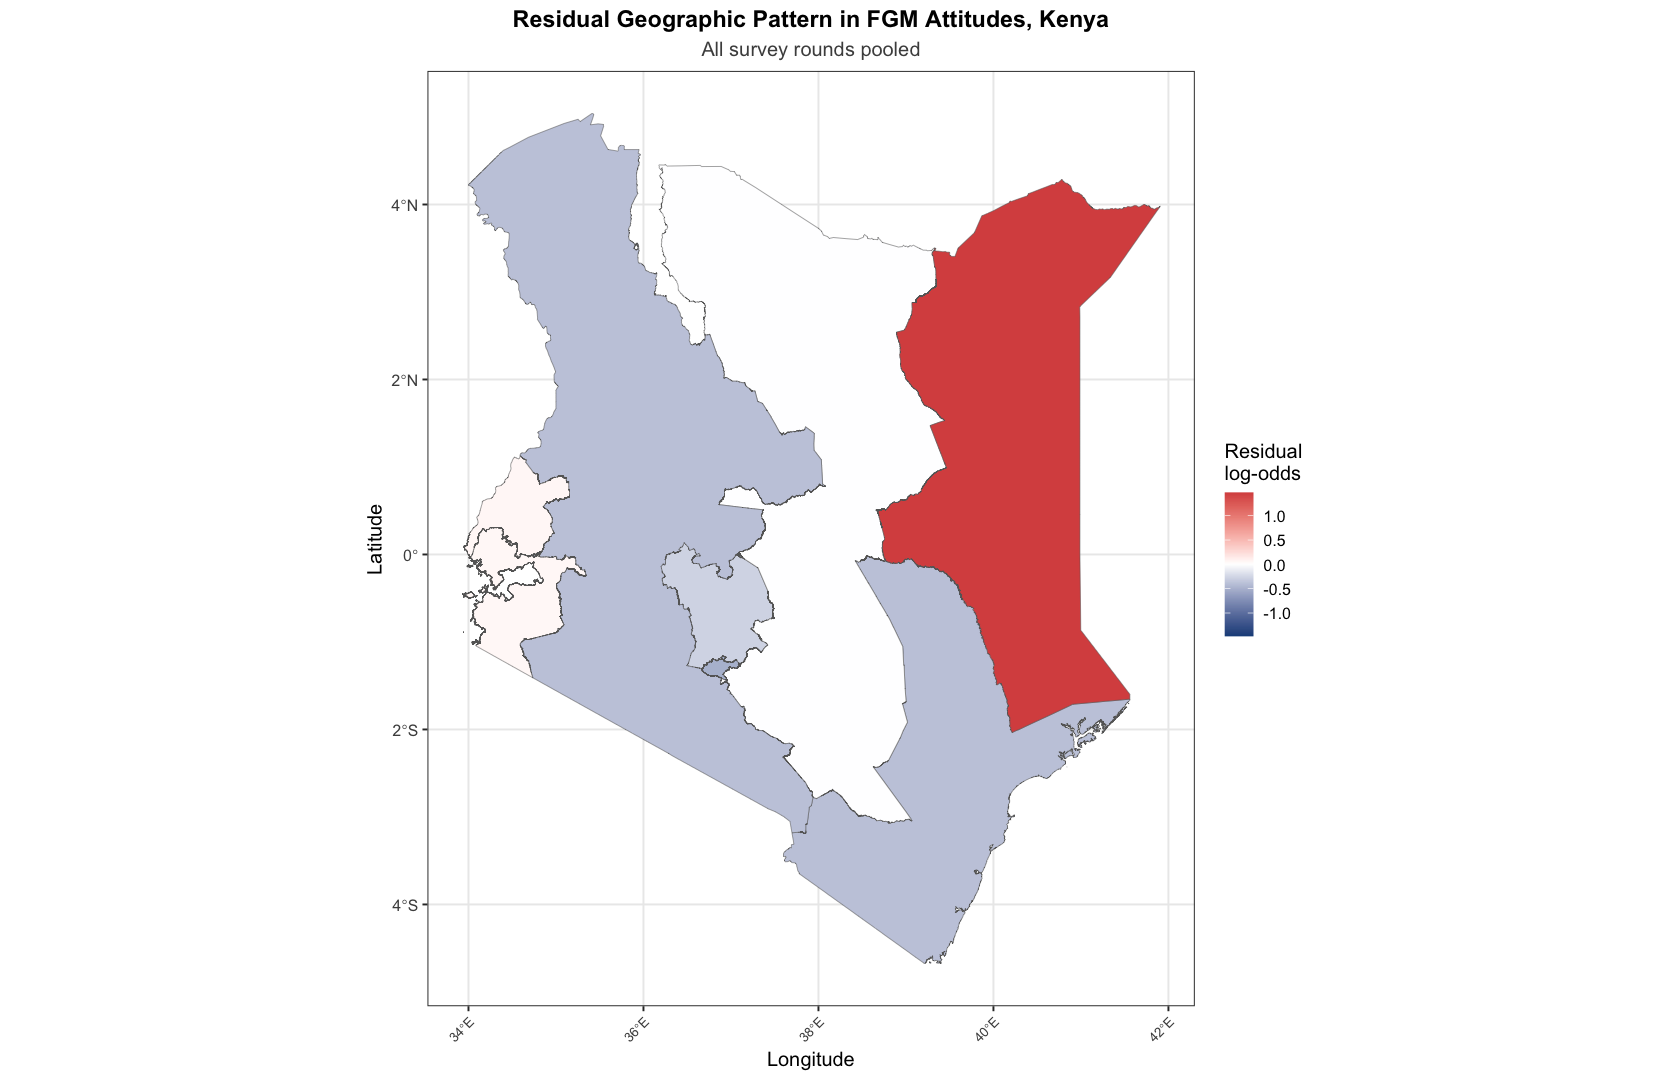

In [12]:
attitude_residual_map <- residual_map(adjusted_model$residual, paste("Residual Geographic Pattern in FGM Attitudes,", country_name),
                                      "All survey rounds pooled")
print(attitude_residual_map)
ggplot2::ggsave(file.path(dirs$maps, paste0(country_iso3, "_attitude_residual_map.png")), attitude_residual_map,
                width = 9, height = 8, dpi = 300, bg = "white")

## 13. Validation and comparison

states_compared,correlation_direct_adjusted,mean_absolute_difference,maximum_absolute_difference
<dbl>,<dbl>,<dbl>,<dbl>
8,1,0.001,0.007


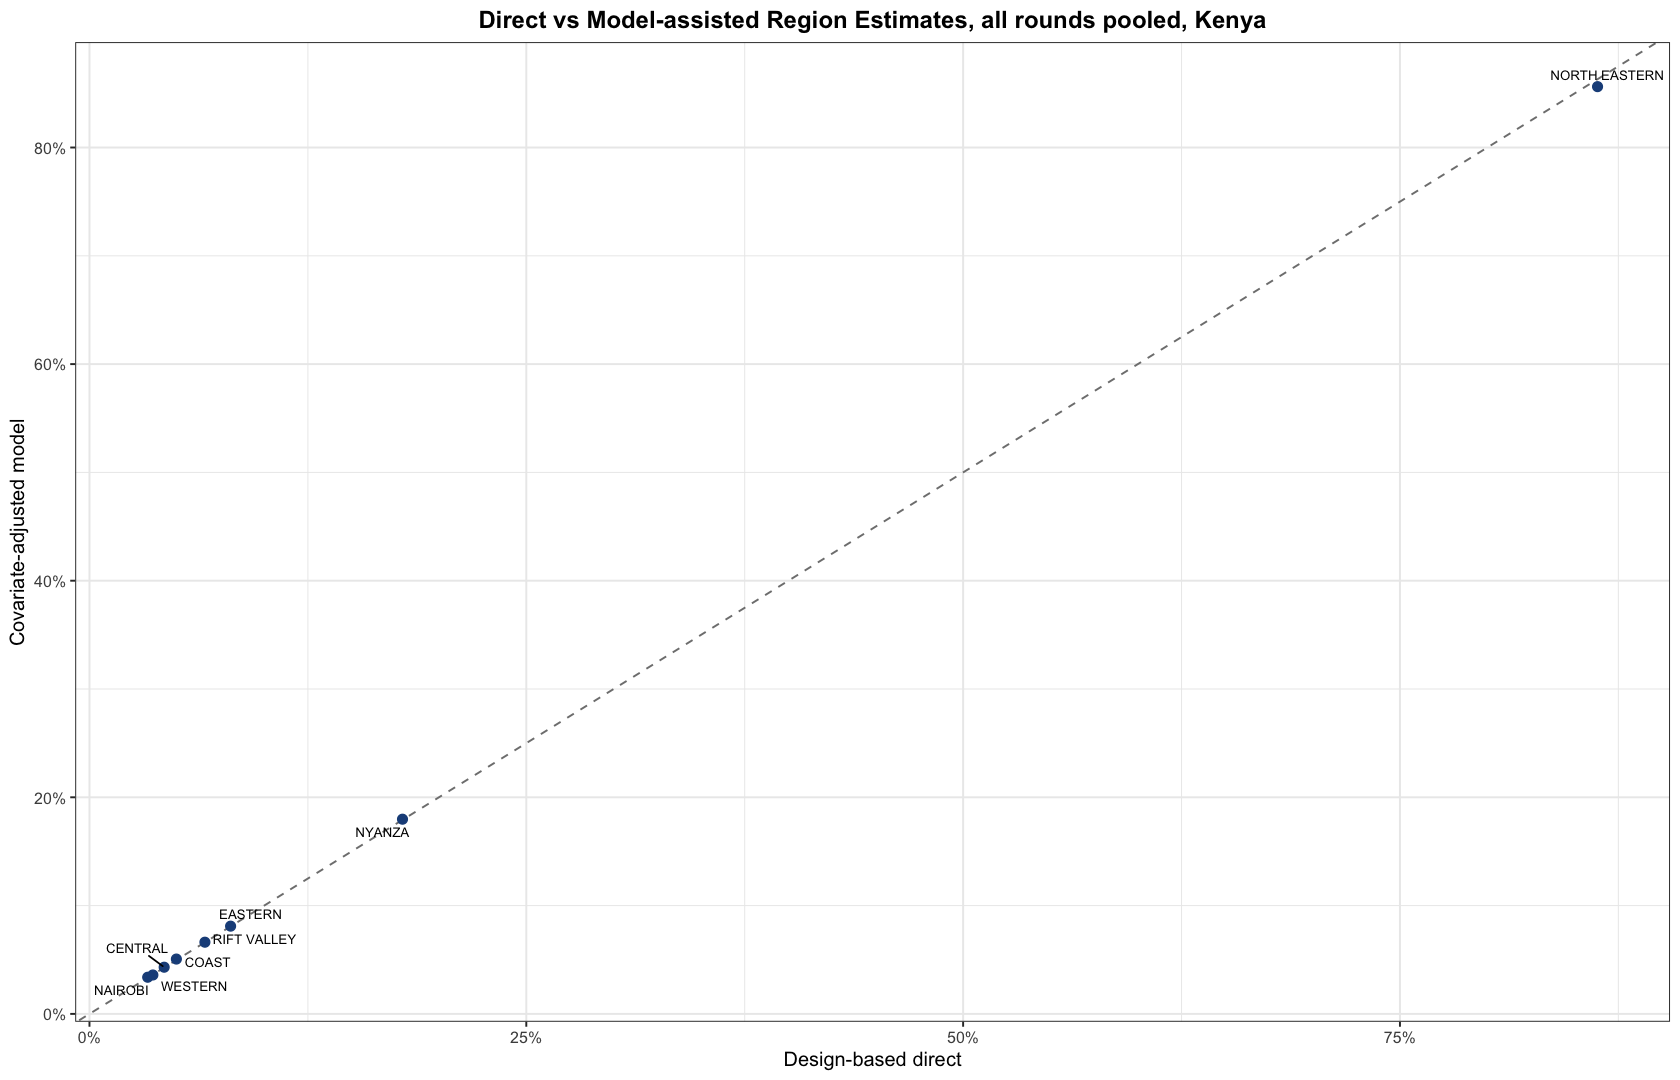

In [13]:
validation_metrics <- adjusted_state |>
  dplyr::summarise(states_compared = sum(stats::complete.cases(direct_support, adjusted_support)),
                   correlation_direct_adjusted = stats::cor(direct_support, adjusted_support, use = "complete.obs"),
                   mean_absolute_difference = mean(abs(adjusted_support - direct_support), na.rm = TRUE),
                   maximum_absolute_difference = max(abs(adjusted_support - direct_support), na.rm = TRUE))
readr::write_csv(validation_metrics, file.path(dirs$validation, paste0(country_iso3, "_attitude_validation_metrics.csv")))
IRdisplay::display(as.data.frame(validation_metrics |> dplyr::mutate(dplyr::across(where(is.numeric), ~ round(.x, 3)))))
validation_plot <- ggplot2::ggplot(adjusted_state, ggplot2::aes(direct_support, adjusted_support)) +
  ggplot2::geom_abline(slope = 1, intercept = 0, linetype = "dashed", color = "grey50") +
  ggplot2::geom_point(color = "#1D4E89", size = 2.4) +
  ggrepel::geom_text_repel(ggplot2::aes(label = region), size = 2.8, seed = 1, max.overlaps = 15) +
  ggplot2::scale_x_continuous(labels = scales::percent_format(accuracy = 1)) +
  ggplot2::scale_y_continuous(labels = scales::percent_format(accuracy = 1)) +
  ggplot2::labs(title = paste("Direct vs Model-assisted Region Estimates, all rounds pooled,", country_name),
                x = "Design-based direct", y = "Covariate-adjusted model") +
  ggplot2::theme_bw(base_size = 12) + ggplot2::theme(plot.title = ggplot2::element_text(face = "bold", hjust = 0.5))
print(validation_plot)
ggplot2::ggsave(file.path(dirs$validation, paste0(country_iso3, "_attitude_validation.png")), validation_plot,
                width = 9, height = 8, dpi = 300, bg = "white")

## 14. National trend across survey rounds

Support for continuation among women who know of FGM, by survey year: design-based
estimates and the pooled model's estimates for each round.

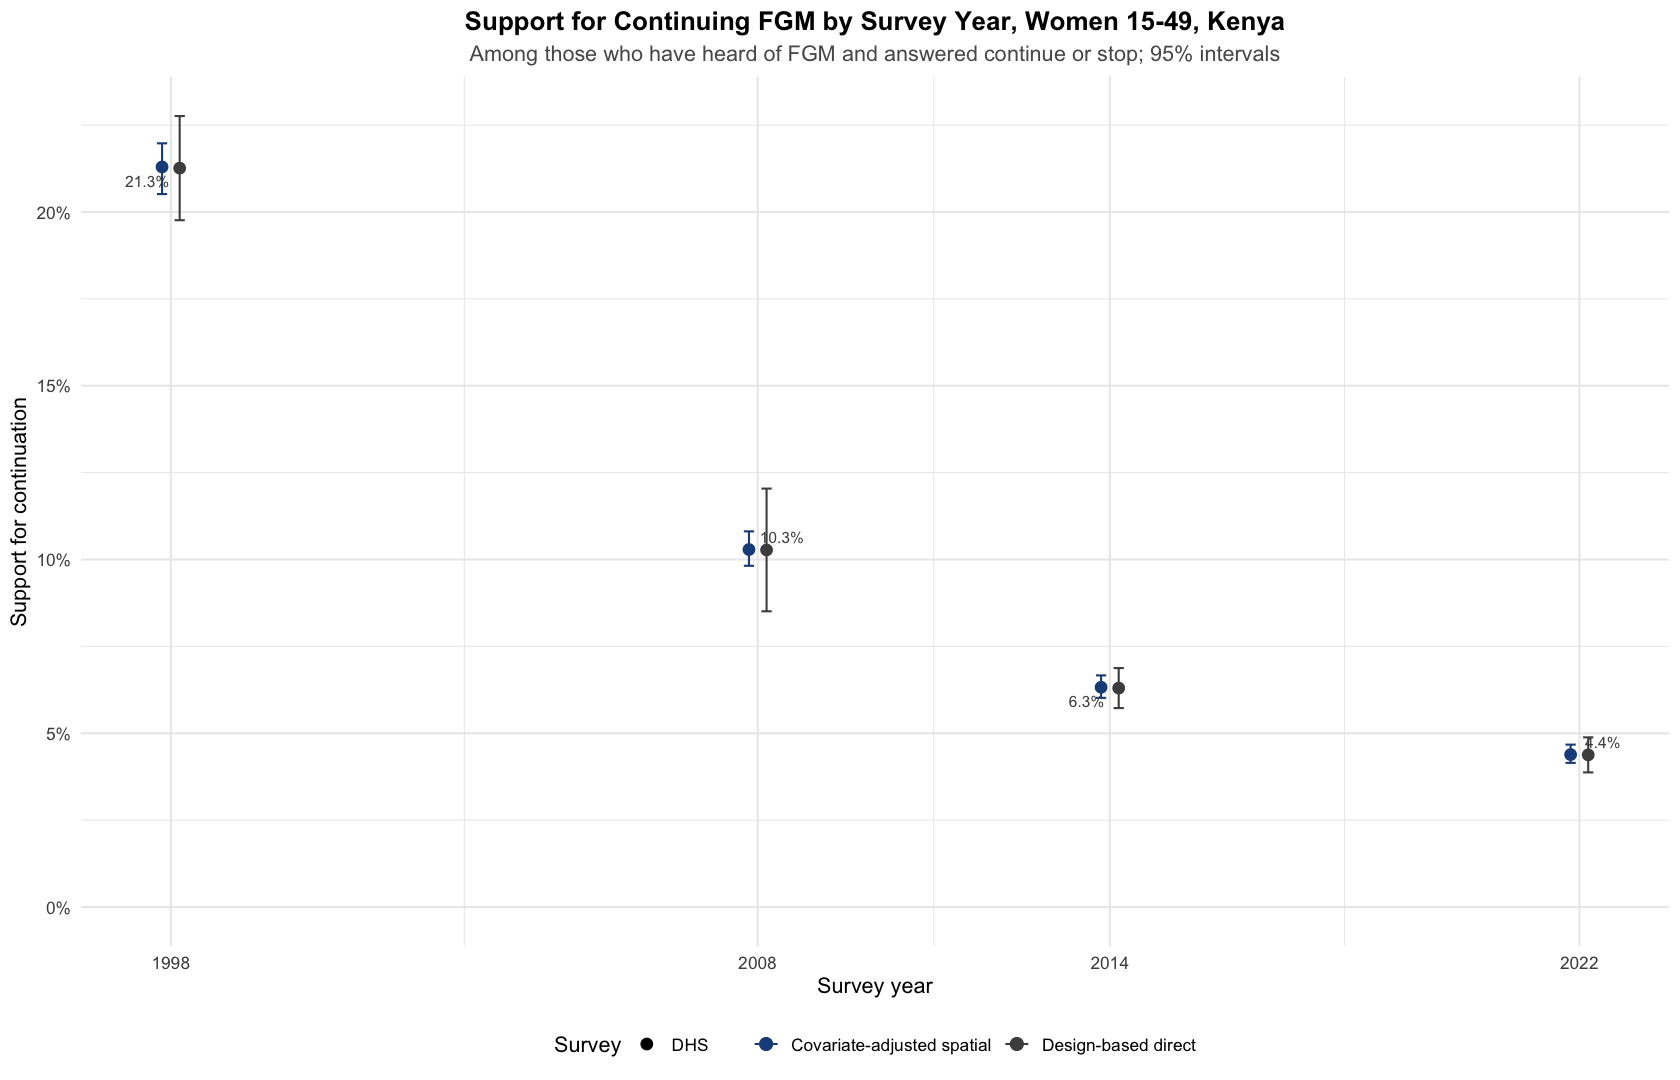

In [14]:
trend_data <- national_comparison |>
  dplyr::left_join(survey_years |> dplyr::mutate(survey_id = as.character(survey_id)), by = "survey_id") |>
  dplyr::filter(method %in% c("Design-based direct", "Covariate-adjusted spatial"))
readr::write_csv(trend_data, file.path(dirs$trends, paste0(country_iso3, "_attitude_national_trend.csv")))
trend_plot <- ggplot2::ggplot(trend_data, ggplot2::aes(round_year, estimate, color = method, shape = survey_type)) +
  ggplot2::geom_errorbar(ggplot2::aes(ymin = lower_ci, ymax = upper_ci), width = 0.35, position = ggplot2::position_dodge(0.6)) +
  ggplot2::geom_point(size = 3.2, position = ggplot2::position_dodge(0.6)) +
  ggrepel::geom_text_repel(data = trend_data |> dplyr::filter(method == "Design-based direct"),
                           ggplot2::aes(label = scales::percent(estimate, accuracy = 0.1)), size = 3.3, seed = 1, show.legend = FALSE) +
  ggplot2::scale_color_manual(values = c("Design-based direct" = "grey30", "Covariate-adjusted spatial" = "#1D4E89")) +
  ggplot2::scale_x_continuous(breaks = sort(unique(trend_data$round_year))) +
  ggplot2::scale_y_continuous(labels = scales::percent_format(accuracy = 1), limits = c(0, NA)) +
  ggplot2::labs(title = paste("Support for Continuing FGM by Survey Year, Women 15-49,", country_name),
                subtitle = "Among those who have heard of FGM and answered continue or stop; 95% intervals",
                x = "Survey year", y = "Support for continuation", color = NULL, shape = "Survey") +
  ggplot2::theme_minimal(base_size = 13) +
  ggplot2::theme(plot.title = ggplot2::element_text(face = "bold", hjust = 0.5),
                 plot.subtitle = ggplot2::element_text(hjust = 0.5, color = "grey35"), legend.position = "bottom")
print(trend_plot)
ggplot2::ggsave(file.path(dirs$trends, paste0(country_iso3, "_attitude_national_trend.png")), trend_plot, width = 11, height = 7, dpi = 300, bg = "white")

## Interpretation and limitations

- The design-based national and region estimates are the survey-design benchmark.
- Models pool all rounds with normalized survey weights in a pseudo-likelihood and a
  survey-round term; their intervals are pseudo-posterior, not fully design-based. Pooled
  provincial estimates describe 1998–2022 as a whole; cohort maps and the trend show change.
- Estimates apply to women aged 15–49 who have heard of FGM and gave a continue/stop
  answer.
- Predictors a round does not collect (wealth in DHS 1998) are kept as an "unknown" category
  in the pooled model.
- DHS 1998 offered only "continue", "discontinue" and "don't know", with no "depends" option, so
  some respondents who would otherwise have said "depends" chose one of the two answers.
- Regions are the 8 former provinces; DHS 2022 counties are mapped to their province.
- Random-forest importance is descriptive and ranks predictors without implying causality.

In [15]:
cat("Attitude analysis completed. Selected predictors:", paste(selected_predictors, collapse = ", "), "\n")
cat("All outputs saved to:", normalizePath(output_dir), "\n")

Attitude analysis completed. Selected predictors: own_status, age, region, education, ethnicity, religion, urban_rural, wealth 


All outputs saved to: /Users/jkakai/Desktop/Main/Melaningod/UNFPA/Root/Working Folder/Final FGM Results/Kenya/V2/03_Outputs/KEN/Attitude_Women 


# Part B — Men's attitudes

Same steps as Part A, applied to men aged 15–49 in the DHS men's recodes (2014 and 2022). Own FGM status
does not apply to men, so age is the only predictor kept a priori. Section 15 compares men
with women in the rounds that asked both.

## 0. Configuration

In [16]:
country_name <- "Kenya"
country_iso3 <- "KEN"

project_root <- if (dir.exists("../02_Data")) ".." else "."
analysis_dir <- file.path(project_root, "02_Data", "processed", country_iso3, "analysis")
output_dir <- file.path(project_root, "03_Outputs", country_iso3, "Attitude_Men")
dirs <- list(
  screening = file.path(output_dir, "01_Predictor_Screening"),
  direct = file.path(output_dir, "02_Direct_Estimates"),
  models = file.path(output_dir, "03_Model_Estimates"),
  maps = file.path(output_dir, "04_Maps"),
  trends = file.path(output_dir, "05_Trends"),
  validation = file.path(output_dir, "06_Validation"),
  comparison = file.path(output_dir, "07_Men_vs_Women")
)
for (d in dirs) dir.create(d, recursive = TRUE, showWarnings = FALSE)

shapefile_path <- file.path(project_root, "02_Data", "processed", "KEN", "boundaries", "KEN_provinces.shp")
region_var_shapefile <- "PROVINCE"
# Region keys as in the harmonized data: upper case, hyphens as spaces ("CENTRE EST").
standardize_region <- function(x) toupper(as.character(x)) |> stringr::str_replace_all("[^A-Z ]", " ") |> stringr::str_squish()
posterior_draws <- 200L
minimum_cohort_cell_n <- 10L
vif_threshold <- 2
missingness_threshold <- 0.30
round_order <- c("DHS 1998", "DHS 2003", "DHS 2008", "DHS 2014", "DHS 2022")
set.seed(20260918)
options(repr.plot.width = 14, repr.plot.height = 9, width = 200)
cat("Configured for:", country_name, "| outputs:", normalizePath(output_dir, mustWork = FALSE), "\n")

Configured for: Kenya | outputs: /Users/jkakai/Desktop/Main/Melaningod/UNFPA/Root/Working Folder/Final FGM Results/Kenya/V2/03_Outputs/KEN/Attitude_Men 


## 1. Setup

In [17]:
suppressPackageStartupMessages({
  library(tidyverse)
  library(survey)
  library(sf)
  library(spdep)
  library(INLA)
  library(randomForest)
  library(car)
})
options(survey.lonely.psu = "adjust")
theme_set(ggplot2::theme_minimal(base_size = 12))

## 2. Load the attitude data

In [18]:
attitude_all <- readRDS(file.path(analysis_dir, paste0(country_iso3, "_attitude_men.rds"))) |>
  dplyr::mutate(survey_id = factor(survey_id, levels = intersect(round_order, unique(survey_id))))
if (!"birth_cohort" %in% names(attitude_all)) {
  # Men's files give age only; birth year is approximated as survey year minus age.
  attitude_all <- attitude_all |>
    dplyr::mutate(birth_year = round_year - age,
                  birth_cohort = as.character(cut(birth_year, breaks = seq(1950, 2025, by = 5), right = FALSE,
                                                  labels = paste0(seq(1950, 2020, by = 5), " to ", seq(1954, 2024, by = 5)))))
}
survey_years <- attitude_all |> dplyr::distinct(survey_id, survey_type, round_year) |> dplyr::arrange(survey_id)

IRdisplay::display(as.data.frame(attitude_all |> dplyr::group_by(survey_id) |>
  dplyr::summarise(respondents = dplyr::n(), supports_continuation = sum(supports_continuation == 1),
                   supports_stopping = sum(supports_continuation == 0),
                   unweighted_pct_continue = round(100 * mean(supports_continuation), 1), .groups = "drop")))

survey_id,respondents,supports_continuation,supports_stopping,unweighted_pct_continue
<fct>,<int>,<int>,<int>,<dbl>
DHS 2014,11507,1518,0,151800
DHS 2022,12878,1237,0,123700


## 3. Attitude-specific predictor screening

Missingness is checked by round. Random-forest permutation importance is computed on a
pooled sample (up to 3,000 respondents per round) and used only for ranking.
Age are retained a priori.

In [19]:
candidate_predictors <- c("age", "education", "wealth", "religion", "ethnicity", "urban_rural", "region")

missingness <- attitude_all |>
  dplyr::group_by(survey_id) |>
  dplyr::summarise(dplyr::across(dplyr::all_of(candidate_predictors), ~ round(mean(is.na(.)), 3)), .groups = "drop")
readr::write_csv(missingness, file.path(dirs$screening, paste0(country_iso3, "_attitude_missingness_by_round.csv")))
IRdisplay::display(as.data.frame(missingness))

# Own FGM status uses a 0.5 completeness rule so a strict threshold cannot drop it in older rounds.
predictor_thresholds <- ifelse(candidate_predictors == "own_status", 0.5, missingness_threshold)
eligible_predictors <- candidate_predictors[colMeans(is.na(attitude_all[candidate_predictors])) < predictor_thresholds]

rf_data <- attitude_all |>
  dplyr::group_by(survey_id) |> dplyr::slice_sample(n = 3000) |> dplyr::ungroup() |>
  dplyr::select(supports_continuation, dplyr::all_of(eligible_predictors)) |>
  tidyr::drop_na() |>
  dplyr::mutate(supports_continuation = factor(supports_continuation),
                dplyr::across(dplyr::where(is.character), as.factor))

rf_model <- randomForest::randomForest(supports_continuation ~ ., data = rf_data, ntree = 500, importance = TRUE)
importance_ranked <- randomForest::importance(rf_model) |> as.data.frame() |>
  tibble::rownames_to_column("variable") |> dplyr::arrange(dplyr::desc(MeanDecreaseAccuracy))
cat("Rows in feature screen:", nrow(rf_data), "\n")
print(importance_ranked)
readr::write_csv(importance_ranked, file.path(dirs$screening, paste0(country_iso3, "_attitude_feature_importance.csv")))

survey_id,age,education,wealth,religion,ethnicity,urban_rural,region
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
DHS 2014,0,0,0,0,0.001,0,0
DHS 2022,0,0,0,0,0.000,0,0


Rows in feature screen: 5992 


     variable          0          1 MeanDecreaseAccuracy MeanDecreaseGini
1   ethnicity 38.9740418 28.5759380            50.853593        191.29476
2      region 24.5186333 36.5000624            44.846335        153.79746
3    religion 19.0540270 18.3754682            28.817267         67.87050
4   education 15.5050196 19.0105476            24.724054         58.46947
5      wealth 16.3400938 15.5293305            24.191181         56.58690
6 urban_rural 19.6087746  0.1086159            19.094643         17.54618
7         age -0.7786229 -2.5175719            -1.877657        115.44297


## 4. Collinearity and final predictor selection

In [20]:
vif_check_model <- stats::glm(stats::reformulate(eligible_predictors, response = "supports_continuation"),
                              data = rf_data, family = stats::binomial())
vif_raw <- car::vif(vif_check_model)
vif_adjusted <- if (is.matrix(vif_raw)) vif_raw[, "GVIF^(1/(2*Df))"] else sqrt(vif_raw)
vif_table <- tibble::tibble(variable = names(vif_adjusted), adjusted_vif = as.numeric(vif_adjusted)) |>
  dplyr::arrange(dplyr::desc(adjusted_vif))
print(vif_table)
vif_flagged <- vif_table$variable[vif_table$adjusted_vif > vif_threshold]
selected_predictors <- unique(c("age", setdiff(importance_ranked$variable, vif_flagged)))
selected_predictors <- selected_predictors[selected_predictors %in% eligible_predictors]
cat("Final attitude predictor list:", paste(selected_predictors, collapse = ", "), "\n")
cat("Region is represented by the BYM2 effect rather than a fixed effect.\n")
readr::write_csv(vif_table, file.path(dirs$screening, paste0(country_iso3, "_attitude_vif.csv")))
readr::write_csv(tibble::tibble(variable = selected_predictors),
                 file.path(dirs$screening, paste0(country_iso3, "_attitude_selected_predictors.csv")))

# A tibble: 7 × 2
  variable    adjusted_vif
  <chr>              <dbl>
1 region              1.43
2 ethnicity           1.30
3 urban_rural         1.28
4 religion            1.27
5 education           1.11
6 wealth              1.10
7 age                 1.05


Final attitude predictor list: age, ethnicity, region, religion, education, wealth, urban_rural 


Region is represented by the BYM2 effect rather than a fixed effect.


## 5. Mixed-variable association matrix

Absolute Spearman correlation (numeric pairs), bias-corrected Cramér's V (categorical
pairs) and the correlation ratio (mixed pairs), on the pooled screening sample.

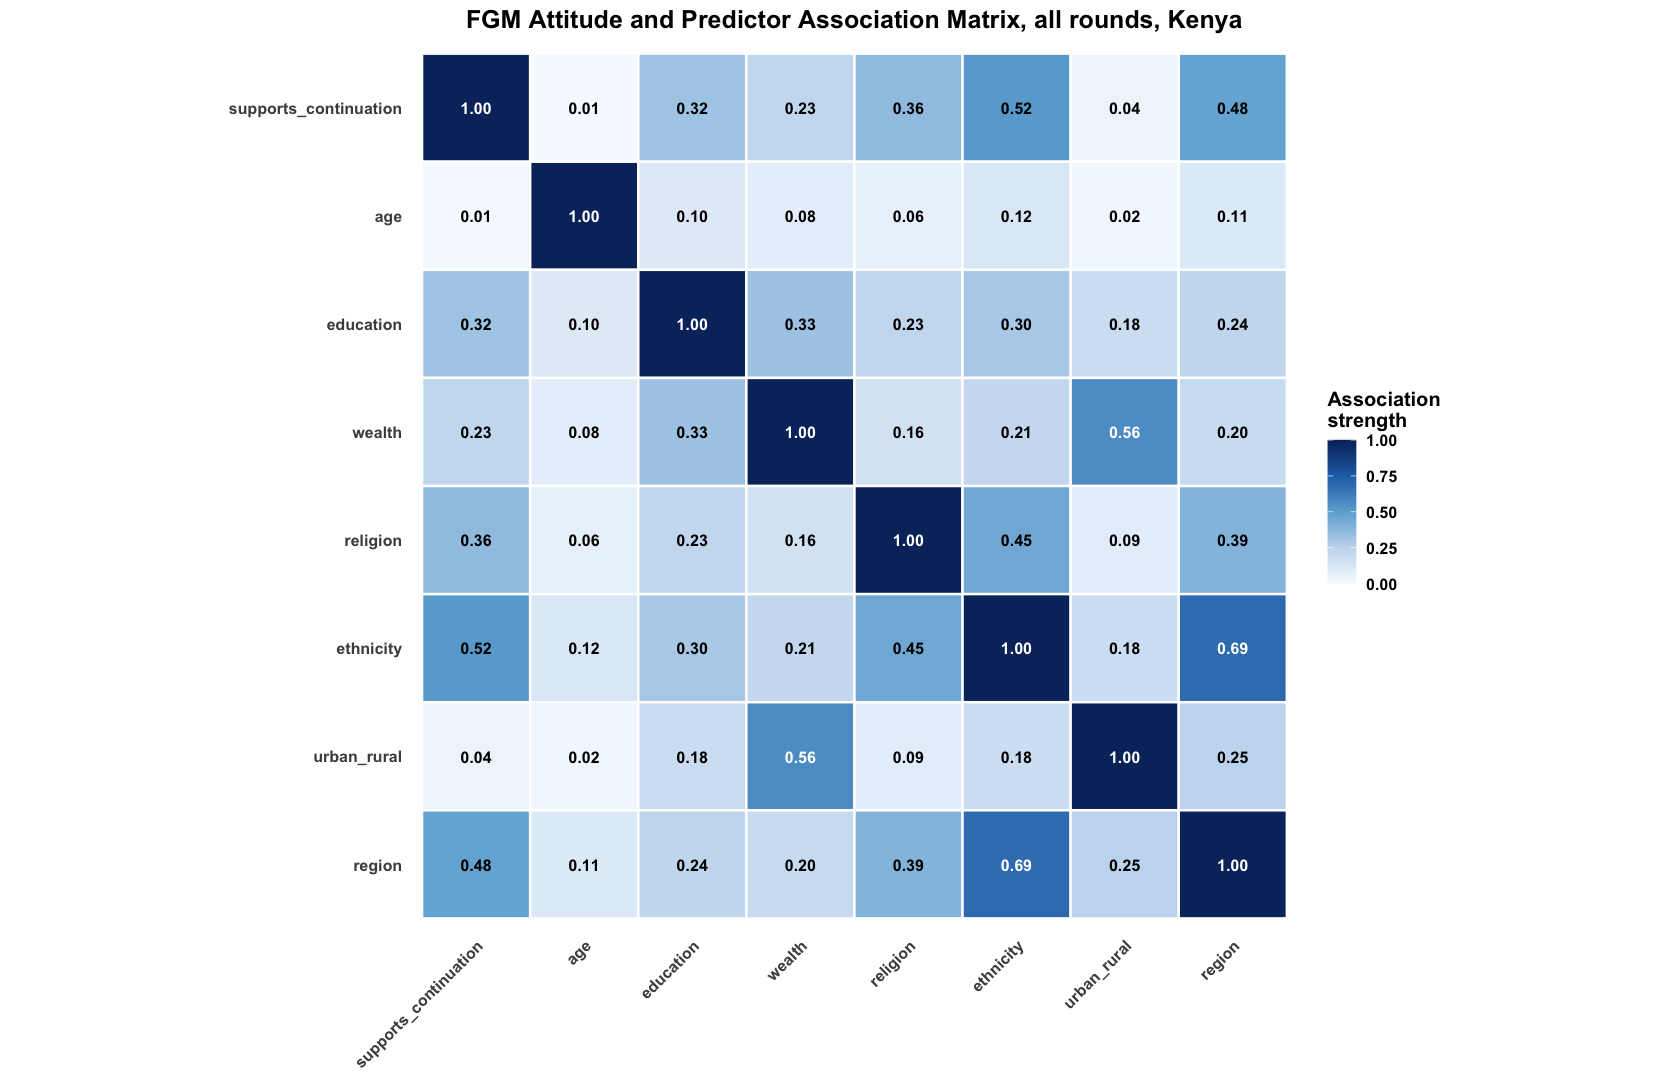

In [21]:
cramers_v_corrected <- function(x, y) {
  keep <- stats::complete.cases(x, y); x <- droplevels(as.factor(x[keep])); y <- droplevels(as.factor(y[keep]))
  if (length(x) == 0L || nlevels(x) < 2L || nlevels(y) < 2L) return(NA_real_)
  tab <- table(x, y); chi2 <- suppressWarnings(as.numeric(stats::chisq.test(tab, correct = FALSE)$statistic))
  n <- sum(tab); r <- nrow(tab); k <- ncol(tab)
  phi2c <- max(0, chi2 / n - ((k - 1) * (r - 1)) / (n - 1))
  den <- min(r - ((r - 1)^2) / (n - 1) - 1, k - ((k - 1)^2) / (n - 1) - 1)
  if (!is.finite(den) || den <= 0) return(NA_real_)
  sqrt(phi2c / den)
}
correlation_ratio <- function(x_numeric, y_category) {
  keep <- stats::complete.cases(x_numeric, y_category)
  x <- as.numeric(x_numeric[keep]); y <- droplevels(as.factor(y_category[keep]))
  if (length(unique(x)) < 2L || nlevels(y) < 2L) return(NA_real_)
  between <- sum(vapply(split(x, y), function(z) length(z) * (mean(z) - mean(x))^2, numeric(1L)))
  sqrt(max(0, min(1, between / sum((x - mean(x))^2))))
}
mixed_association <- function(x, y) {
  if (is.numeric(x) && is.numeric(y)) return(abs(stats::cor(x, y, method = "spearman", use = "complete.obs")))
  if (!is.numeric(x) && !is.numeric(y)) return(cramers_v_corrected(x, y))
  if (is.numeric(x)) correlation_ratio(x, y) else correlation_ratio(y, x)
}
association_data <- rf_data |> dplyr::mutate(supports_continuation = factor(supports_continuation, labels = c("Stop", "Continue")))
association_names <- names(association_data)
association_matrix <- outer(seq_along(association_names), seq_along(association_names), Vectorize(function(i, j)
  if (i == j) 1 else mixed_association(association_data[[i]], association_data[[j]])))
dimnames(association_matrix) <- list(association_names, association_names)
association_long <- as.data.frame(association_matrix) |> tibble::rownames_to_column("variable_y") |>
  tidyr::pivot_longer(-variable_y, names_to = "variable_x", values_to = "association") |>
  dplyr::mutate(variable_x = factor(variable_x, levels = association_names),
                variable_y = factor(variable_y, levels = rev(association_names)))
association_plot <- ggplot2::ggplot(association_long, ggplot2::aes(variable_x, variable_y, fill = association)) +
  ggplot2::geom_tile(color = "white", linewidth = 0.7) +
  ggplot2::geom_text(ggplot2::aes(label = sprintf("%.2f", association), color = association >= 0.55), fontface = "bold", size = 3.4) +
  ggplot2::scale_fill_gradientn(colors = c("#F7FBFF", "#C6DBEF", "#6BAED6", "#2171B5", "#08306B"), limits = c(0, 1),
                                name = "Association\nstrength", na.value = "grey85") +
  ggplot2::scale_color_manual(values = c(`FALSE` = "black", `TRUE` = "white"), guide = "none") +
  ggplot2::coord_fixed() +
  ggplot2::labs(title = paste("FGM Attitude and Predictor Association Matrix, all rounds,", country_name), x = NULL, y = NULL) +
  ggplot2::theme_minimal(base_size = 12) +
  ggplot2::theme(text = ggplot2::element_text(face = "bold"), plot.title = ggplot2::element_text(hjust = 0.5, size = 15),
                 axis.text.x = ggplot2::element_text(angle = 45, hjust = 1), panel.grid = ggplot2::element_blank())
print(association_plot)
ggplot2::ggsave(file.path(dirs$screening, paste0(country_iso3, "_attitude_association_matrix.png")), association_plot,
                width = 10, height = 8, dpi = 300, bg = "white")

## 6. Design-based direct estimates (pooled)

One pooled survey design across all rounds (each survey keeps its own clusters and strata):
pooled estimates by region, and national estimates by survey round for the trend in
section 14. These remain the design-based benchmark.

In [22]:
# Pooled survey-weighted BYM2 model on all survey rounds together. Weights are mean-one
# within each survey, so every round contributes in proportion to its sample size; a
# survey-round term absorbs level differences between rounds. Covariates a round did not
# collect are kept as an "unknown" category so no round is dropped. Respondents with
# identical predictors and outcome are grouped with summed weights, which leaves the
# weighted likelihood unchanged.
prepare_pooled <- function(data, outcome, covariates) {
  data |>
    dplyr::filter(!is.na(.data[[outcome]]), is.finite(weight), weight > 0, is.finite(age),
                  !is.na(birth_cohort), region %in% region_keys) |>
    dplyr::mutate(region_id = match(region, region_keys),
                  dplyr::across(dplyr::all_of(covariates), ~ factor(tidyr::replace_na(as.character(.x), "unknown"))),
                  survey_id = factor(as.character(survey_id)),
                  birth_cohort = as.character(birth_cohort),
                  age_id = as.integer(age - min(age) + 1L)) |>
    dplyr::group_by(dplyr::across(dplyr::all_of(c("region", "region_id", "age_id", "birth_cohort", "survey_id",
                                                  covariates, outcome)))) |>
    dplyr::summarise(survey_weight = sum(weight), n = dplyr::n(), .groups = "drop")
}

fit_pooled <- function(grouped, outcome, covariates, spatial_only = FALSE, n_draws = posterior_draws, seed = 1L) {
  fixed <- if (spatial_only) "1" else paste(c("survey_id", covariates), collapse = " + ")
  age_term <- if (spatial_only) "" else " + f(age_id, model = 'rw2', constr = TRUE, scale.model = TRUE)"
  model_formula <- stats::as.formula(paste0(outcome, " ~ ", fixed, age_term,
    " + f(region_id, model = 'bym2', graph = adjacency_matrix, scale.model = TRUE)"))
  fit <- INLA::inla(model_formula, family = "binomial", data = grouped, Ntrials = rep(1L, nrow(grouped)),
                    weights = grouped$survey_weight,
                    control.predictor = list(compute = TRUE, link = 1),
                    control.compute = list(config = TRUE, dic = TRUE, waic = TRUE),
                    control.inla = list(control.vb = list(enable = FALSE)),
                    # Weakly informative N(0, sd 2) prior on the fixed effects (Kenya): groups with
                    # almost no cases (e.g. Kikuyu girls) otherwise give unbounded coefficients and
                    # inflated, unstable predictions in low-prevalence provinces.
                    control.fixed = list(prec = 0.25, prec.intercept = 0.001))
  set.seed(seed)
  samples <- INLA::inla.posterior.sample(n_draws, fit, use.improved.mean = FALSE, skew.corr = FALSE)
  rows <- grep("^Predictor:", rownames(samples[[1]]$latent))
  rows <- rows[order(as.integer(sub("^Predictor:", "", rownames(samples[[1]]$latent)[rows])))]
  stopifnot(length(rows) == nrow(grouped))
  w <- grouped$survey_weight
  weighted_probs <- lapply(samples, function(s) stats::plogis(as.numeric(s$latent[rows, 1L])) * w)
  rm(samples)
  groupings <- list(
    state = grouped$region,
    state_cohort = paste(grouped$region, grouped$birth_cohort, sep = "|"),
    cohort = grouped$birth_cohort,
    survey = as.character(grouped$survey_id),
    national = rep(country_name, nrow(grouped))
  )
  summaries <- lapply(groupings, function(g) {
    g <- factor(g)
    num <- vapply(weighted_probs, function(pw) as.numeric(rowsum(pw, g)), numeric(nlevels(g)))
    if (is.null(dim(num))) num <- matrix(num, nrow = nlevels(g))
    den <- as.numeric(rowsum(w, g))
    est <- num / den
    tibble::tibble(group = levels(g), estimate = rowMeans(est),
                   lower_ci = apply(est, 1, stats::quantile, 0.025, names = FALSE),
                   upper_ci = apply(est, 1, stats::quantile, 0.975, names = FALSE),
                   n_unweighted = as.numeric(rowsum(grouped$n, g)), sum_weight = den)
  })
  list(fit = fit, state = summaries$state |> dplyr::rename(region = group),
       state_cohort = summaries$state_cohort |> tidyr::separate(group, c("region", "birth_cohort"), sep = "\\|"),
       cohort = summaries$cohort |> dplyr::rename(birth_cohort = group),
       survey = summaries$survey |> dplyr::rename(survey_id = group),
       national = summaries$national |> dplyr::select(-group),
       fixed = tibble::as_tibble(fit$summary.fixed, rownames = "term"),
       residual = tibble::tibble(region = region_keys,
                                 residual_effect = fit$summary.random$region_id$mean[seq_along(region_keys)]),
       fit_stats = tibble::tibble(dic = fit$dic$dic, waic = fit$waic$waic, rows = nrow(grouped),
                                  respondents = sum(grouped$n)))
}

# Pooled design-based direct estimate by a grouping variable (each survey keeps its own
# clusters and strata inside the pooled design).
pooled_direct <- function(data, outcome, by) {
  d <- data |> dplyr::filter(!is.na(.data[[outcome]]))
  design <- survey::svydesign(ids = ~cluster, strata = ~strata, weights = ~weight, data = d, nest = TRUE)
  est <- survey::svyby(stats::as.formula(paste0("~", outcome)), stats::as.formula(paste0("~", by)), design, survey::svymean)
  tibble::tibble(!!by := est[[by]], direct = as.numeric(est[[outcome]]), se = as.numeric(est$se)) |>
    dplyr::mutate(lower_ci = pmax(direct - 1.96 * se, 0), upper_ci = pmin(direct + 1.96 * se, 1),
                  n = as.integer(table(d[[by]])[as.character(.data[[by]])]))
}

# One map per estimate set (V1 style) and a faceted birth-cohort map.
state_map <- function(estimates, value_col, title_text, subtitle_text, legend_title, fill_limits) {
  map_data <- boundaries |> dplyr::mutate(region = region_keys) |> dplyr::left_join(estimates, by = "region")
  ggplot2::ggplot(map_data) +
    ggplot2::geom_sf(ggplot2::aes(fill = .data[[value_col]]), color = "grey40", linewidth = 0.15) +
    ggplot2::scale_fill_viridis_c(name = legend_title, option = "magma", direction = -1,
                                  labels = scales::percent_format(accuracy = 1), limits = fill_limits,
                                  oob = scales::squish, na.value = "grey90") +
    ggplot2::coord_sf(datum = sf::st_crs(4326)) +
    ggplot2::labs(title = title_text, subtitle = subtitle_text, x = "Longitude", y = "Latitude") +
    ggplot2::theme_bw(base_size = 12) +
    ggplot2::theme(plot.title = ggplot2::element_text(face = "bold", size = 15, hjust = 0.5),
                   plot.subtitle = ggplot2::element_text(hjust = 0.5, color = "grey30"),
                   panel.border = ggplot2::element_rect(color = "grey40", fill = NA, linewidth = 0.4),
                   axis.text.x = ggplot2::element_text(angle = 45, hjust = 1, size = 8))
}
cohort_map <- function(estimates, value_col, title_text, subtitle_text, legend_title, fill_limits) {
  map_data <- boundaries |> dplyr::mutate(region = region_keys) |>
    dplyr::left_join(estimates, by = "region", relationship = "one-to-many") |> dplyr::filter(!is.na(birth_cohort))
  ggplot2::ggplot() +
    ggplot2::geom_sf(data = boundaries, fill = "grey90", color = "grey60", linewidth = 0.1) +
    ggplot2::geom_sf(data = map_data, ggplot2::aes(fill = .data[[value_col]]), color = "grey40", linewidth = 0.12) +
    ggplot2::facet_wrap(~birth_cohort, ncol = 4) +
    ggplot2::scale_fill_viridis_c(name = legend_title, option = "magma", direction = -1,
                                  labels = scales::percent_format(accuracy = 1), limits = fill_limits, oob = scales::squish) +
    ggplot2::labs(title = title_text, subtitle = subtitle_text, x = NULL, y = NULL) +
    ggplot2::theme_bw(base_size = 12) +
    ggplot2::theme(plot.title = ggplot2::element_text(face = "bold", size = 16, hjust = 0.5),
                   plot.subtitle = ggplot2::element_text(hjust = 0.5, color = "grey30"),
                   strip.text = ggplot2::element_text(face = "bold", size = 10),
                   strip.background = ggplot2::element_rect(fill = "grey90", color = "grey40"),
                   axis.text = ggplot2::element_blank(), axis.ticks = ggplot2::element_blank())
}
residual_map <- function(residuals, title_text, subtitle_text) {
  lim <- max(abs(residuals$residual_effect), na.rm = TRUE)
  ggplot2::ggplot(boundaries |> dplyr::mutate(region = region_keys) |> dplyr::left_join(residuals, by = "region")) +
    ggplot2::geom_sf(ggplot2::aes(fill = residual_effect), color = "grey40", linewidth = 0.15) +
    ggplot2::scale_fill_gradient2(name = "Residual\nlog-odds", low = "#1D4E89", mid = "white", high = "#D9534F",
                                  midpoint = 0, limits = c(-lim, lim)) +
    ggplot2::labs(title = title_text, subtitle = subtitle_text, x = "Longitude", y = "Latitude") +
    ggplot2::theme_bw(base_size = 12) +
    ggplot2::theme(plot.title = ggplot2::element_text(face = "bold", size = 14, hjust = 0.5),
                   plot.subtitle = ggplot2::element_text(hjust = 0.5, color = "grey30"),
                   axis.text.x = ggplot2::element_text(angle = 45, hjust = 1, size = 8))
}

In [23]:
design_for <- function(d) survey::svydesign(ids = ~cluster, strata = ~strata, weights = ~weight, data = d, nest = TRUE)
direct_by_region <- pooled_direct(attitude_all, "supports_continuation", "region") |>
  dplyr::rename(direct_support = direct, direct_se = se, direct_lower = lower_ci, direct_upper = upper_ci)
direct_national <- pooled_direct(attitude_all |> dplyr::mutate(survey_id = as.character(survey_id)), "supports_continuation", "survey_id") |>
  dplyr::rename(estimate = direct) |> dplyr::mutate(method = "Design-based direct")
pooled_national_direct <- survey::svymean(~supports_continuation, design_for(attitude_all))
readr::write_csv(direct_national, file.path(dirs$direct, paste0(country_iso3, "_attitude_direct_national_by_round.csv")))
readr::write_csv(direct_by_region, file.path(dirs$direct, paste0(country_iso3, "_attitude_direct_by_region.csv")))
cat("Pooled national support for continuation:", round(100 * as.numeric(stats::coef(pooled_national_direct)), 1), "%\n")
IRdisplay::display(as.data.frame(direct_national |> dplyr::mutate(dplyr::across(c(estimate, lower_ci, upper_ci), ~ round(100 * .x, 1)))))

Pooled national support for continuation: 7.1 %


survey_id,estimate,se,lower_ci,upper_ci,n,method
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<chr>
DHS 2014,9.5,0.004405157,8.6,10.3,11507,Design-based direct
DHS 2022,4.9,0.002418663,4.5,5.4,12878,Design-based direct


## 7. Region boundaries and BYM2 adjacency

In [24]:
boundaries <- sf::st_read(shapefile_path, quiet = TRUE) |> sf::st_make_valid()
region_keys <- standardize_region(boundaries[[region_var_shapefile]])
adjacency <- spdep::poly2nb(boundaries, row.names = region_keys, queen = TRUE)
adjacency_matrix <- spdep::nb2mat(adjacency, style = "B", zero.policy = TRUE)
stopifnot(all(unique(attitude_all$region) %in% region_keys))
cat("Boundary regions:", nrow(boundaries), "\n")

Boundary regions: 8 


## 8–10. Survey-weighted spatial models and posterior estimates (pooled)

As in V1, a spatial-only benchmark and a covariate-adjusted model (the selected predictors
as fixed effects, age as RW2, region as BYM2), each fitted once to all rounds with
normalized survey weights; the adjusted model also has a survey-round term. Predictors a
round did not collect are kept as an "unknown" category. For each posterior draw, fitted
probabilities are averaged with the survey weights within region, region × birth cohort,
survey round and nationally. Intervals are pseudo-posterior.

In [25]:
fixed_covariates <- setdiff(selected_predictors, c("region", "age"))
model_input <- attitude_all
if ("own_status" %in% names(model_input)) {
  model_input <- model_input |>
    dplyr::mutate(own_status = dplyr::case_when(own_status == 1 ~ "Cut", own_status == 0 ~ "Not cut", TRUE ~ NA_character_))
}
grouped <- prepare_pooled(model_input, "supports_continuation", fixed_covariates)
t0 <- Sys.time()
spatial_model <- fit_pooled(grouped, "supports_continuation", fixed_covariates, spatial_only = TRUE, seed = 20260918L)
adjusted_model <- fit_pooled(grouped, "supports_continuation", fixed_covariates, seed = 20260919L)
cat("Pooled models fitted in", round(as.numeric(difftime(Sys.time(), t0, units = "mins")), 1), "min; fixed effects:",
    paste(c("survey round", fixed_covariates), collapse = ", "), "\n")

adjusted_state <- adjusted_model$state |>
  dplyr::rename(adjusted_support = estimate, adjusted_lower = lower_ci, adjusted_upper = upper_ci) |>
  dplyr::left_join(spatial_model$state |> dplyr::select(region, spatial_only = estimate), by = "region") |>
  dplyr::left_join(direct_by_region, by = "region")
adjusted_cohort <- adjusted_model$state_cohort |> dplyr::filter(n_unweighted >= minimum_cohort_cell_n) |>
  dplyr::rename(adjusted_support = estimate)
national_comparison <- dplyr::bind_rows(
  direct_national |> dplyr::select(survey_id, method, estimate, lower_ci, upper_ci),
  adjusted_model$survey |> dplyr::transmute(survey_id, method = "Covariate-adjusted spatial", estimate, lower_ci, upper_ci),
  spatial_model$survey |> dplyr::transmute(survey_id, method = "Spatial only", estimate, lower_ci, upper_ci))
model_fit_comparison <- dplyr::bind_rows(spatial_model$fit_stats |> dplyr::mutate(model = "Spatial only"),
                                         adjusted_model$fit_stats |> dplyr::mutate(model = "Covariate adjusted"))
readr::write_csv(adjusted_state, file.path(dirs$models, paste0(country_iso3, "_attitude_covariate_adjusted_by_region.csv")))
readr::write_csv(adjusted_cohort, file.path(dirs$models, paste0(country_iso3, "_attitude_covariate_adjusted_by_region_cohort.csv")))
readr::write_csv(national_comparison, file.path(dirs$models, paste0(country_iso3, "_attitude_national_comparison_by_round.csv")))
readr::write_csv(model_fit_comparison, file.path(dirs$models, paste0(country_iso3, "_attitude_model_fit.csv")))
readr::write_csv(adjusted_model$fixed, file.path(dirs$models, paste0(country_iso3, "_attitude_fixed_effects.csv")))
readr::write_csv(adjusted_model$residual, file.path(dirs$models, paste0(country_iso3, "_attitude_residual_spatial_effect.csv")))
IRdisplay::display(as.data.frame(model_fit_comparison))
cat("Pooled national support (model):", round(100 * adjusted_model$national$estimate, 1), "%\n")

Pooled models fitted in 0.3 min; fixed effects: survey round, ethnicity, religion, education, wealth, urban_rural 


dic,waic,rows,respondents,model
<dbl>,<dbl>,<int>,<int>,<chr>
11144.405,11161.658,14356,24385,Spatial only
9939.745,9992.486,14356,24385,Covariate adjusted


Pooled national support (model): 7.1 %


## 11. Covariate-adjusted attitude maps (pooled)

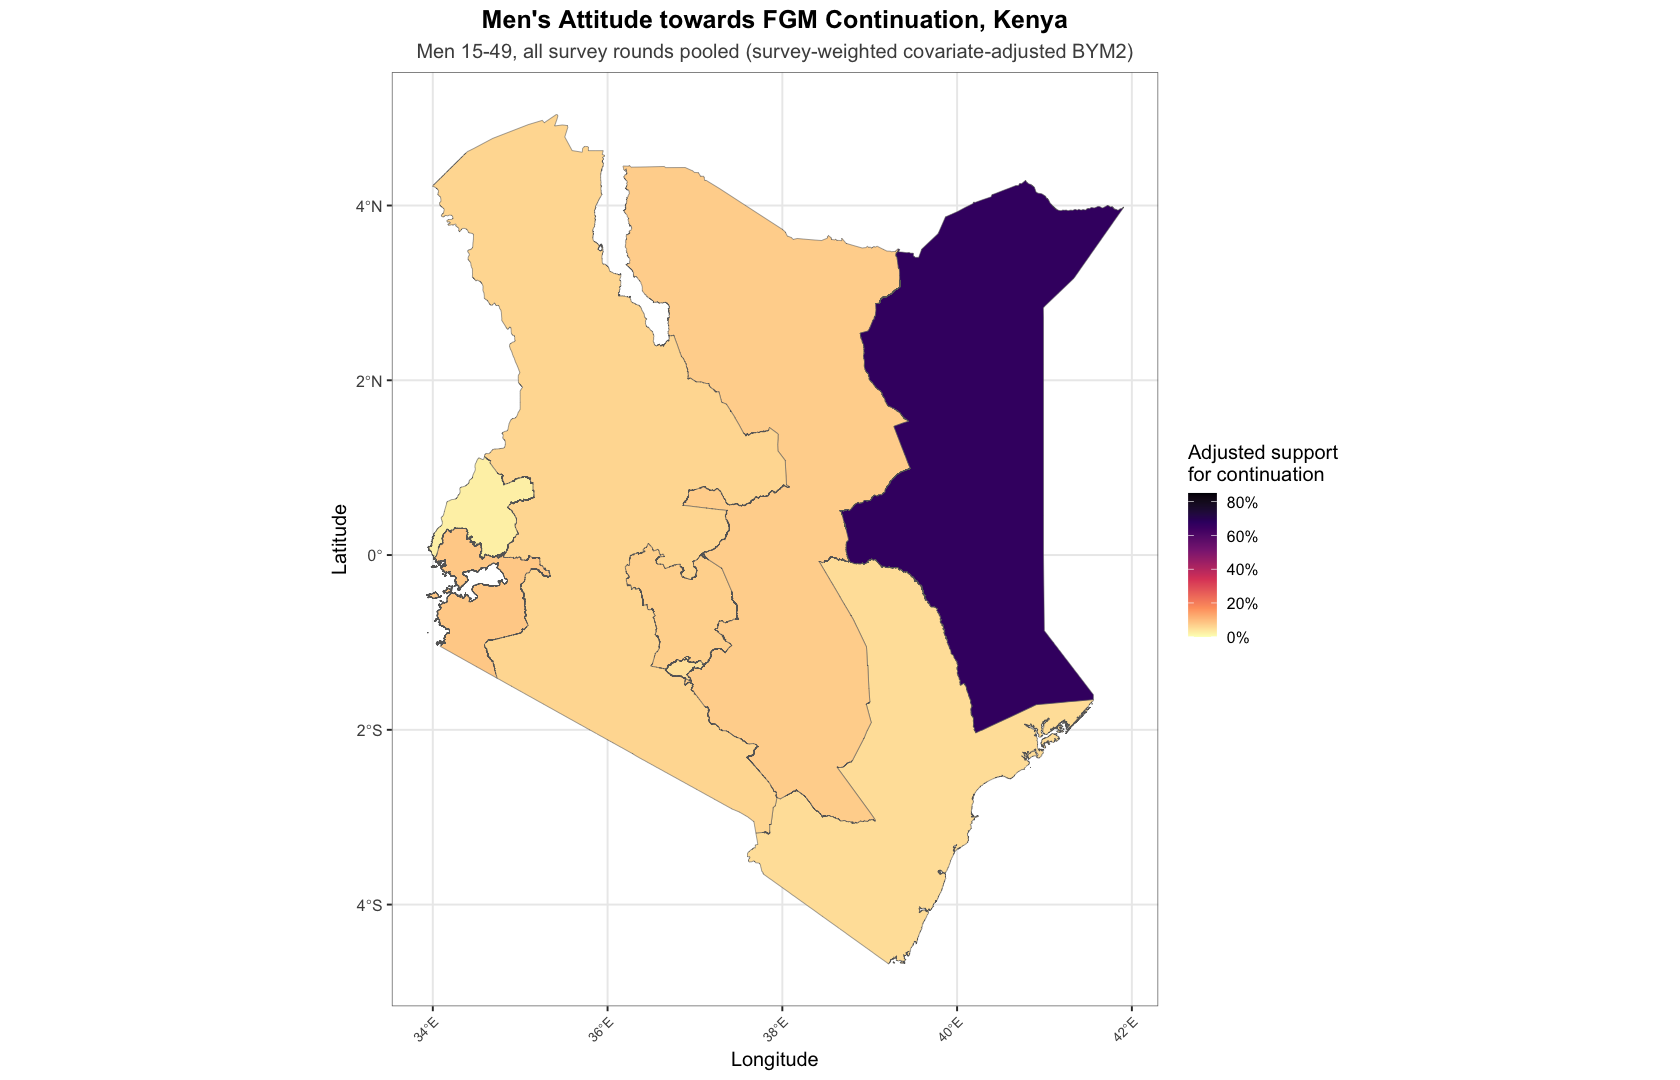

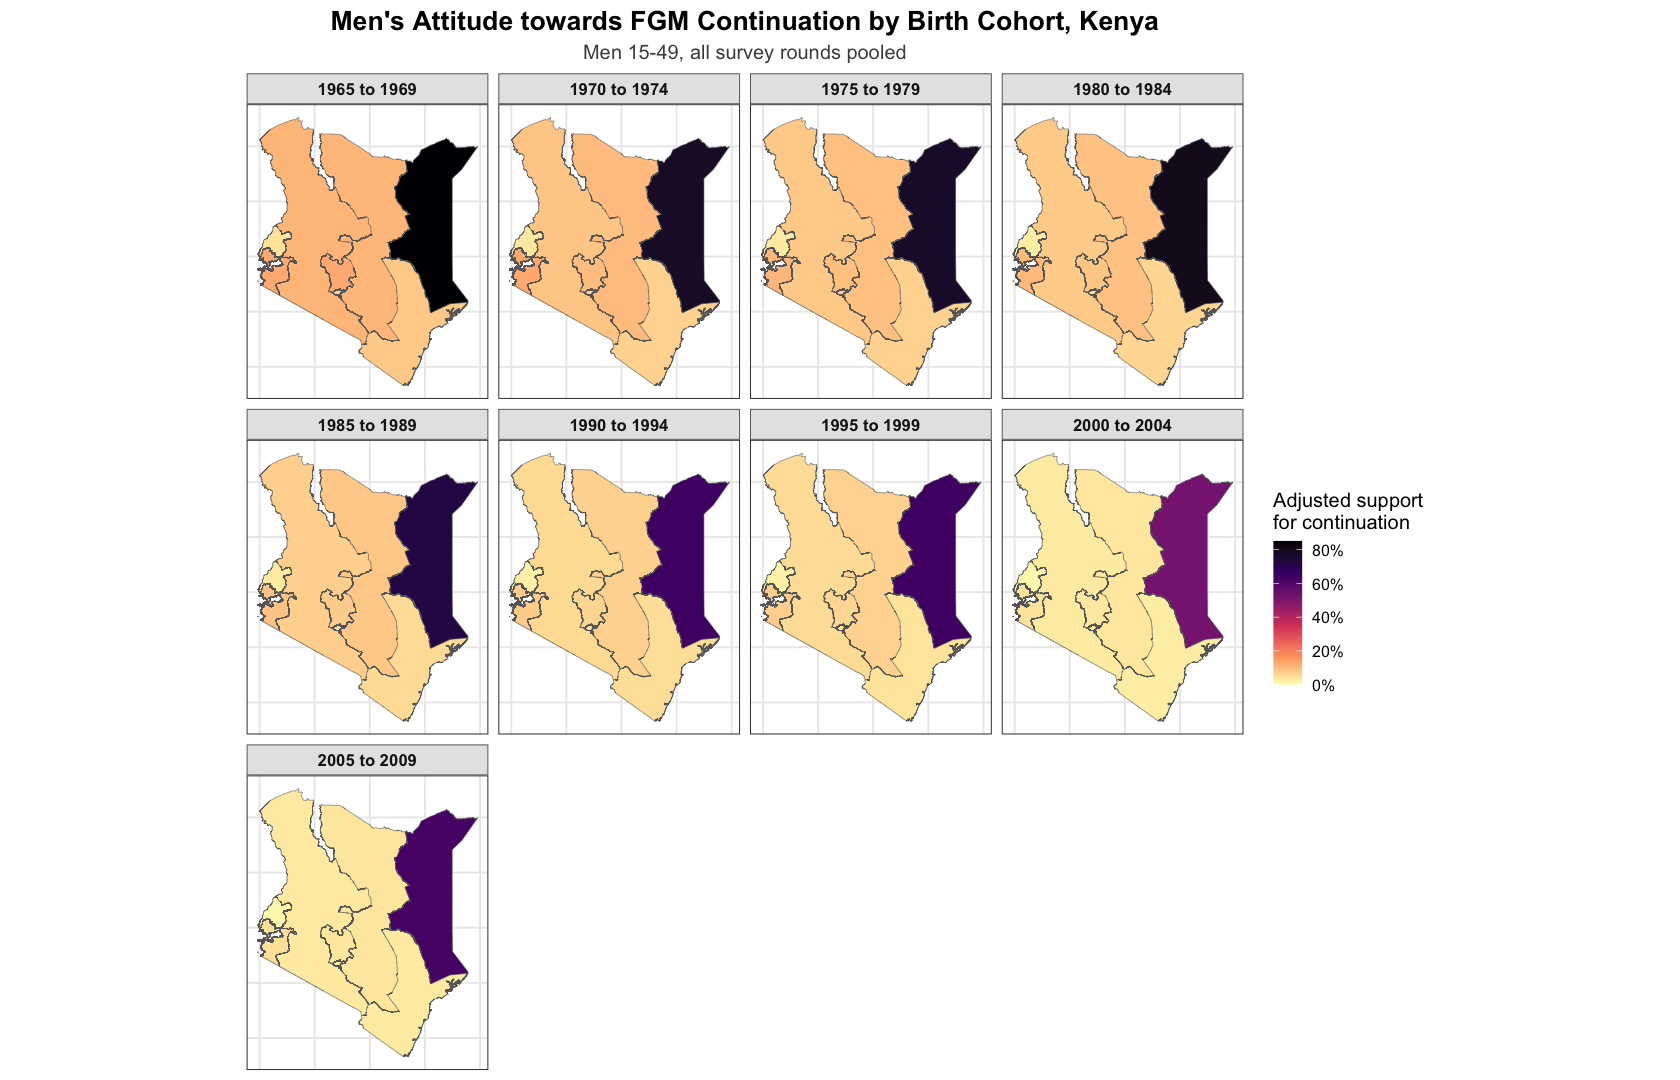

In [26]:
support_fill <- c(0, max(adjusted_state$adjusted_support, adjusted_cohort$adjusted_support))
adjusted_attitude_map <- state_map(adjusted_state, "adjusted_support",
  paste("Men's Attitude towards FGM Continuation,", country_name),
  "Men 15-49, all survey rounds pooled (survey-weighted covariate-adjusted BYM2)", "Adjusted support\nfor continuation", support_fill)
cohort_attitude_map <- cohort_map(adjusted_cohort, "adjusted_support",
  paste("Men's Attitude towards FGM Continuation by Birth Cohort,", country_name),
  "Men 15-49, all survey rounds pooled", "Adjusted support\nfor continuation", support_fill)
print(adjusted_attitude_map); print(cohort_attitude_map)
ggplot2::ggsave(file.path(dirs$maps, paste0(country_iso3, "_attitude_covariate_adjusted_map.png")), adjusted_attitude_map,
                width = 9, height = 8, dpi = 300, bg = "white")
ggplot2::ggsave(file.path(dirs$maps, paste0(country_iso3, "_attitude_covariate_adjusted_map_by_cohort.png")), cohort_attitude_map,
                width = 14, height = 12, dpi = 300, bg = "white")

## 12. Residual geographic pattern (pooled)

The BYM2 effect after adjustment for composition and survey round (relative log-odds, not
an attitude prevalence).

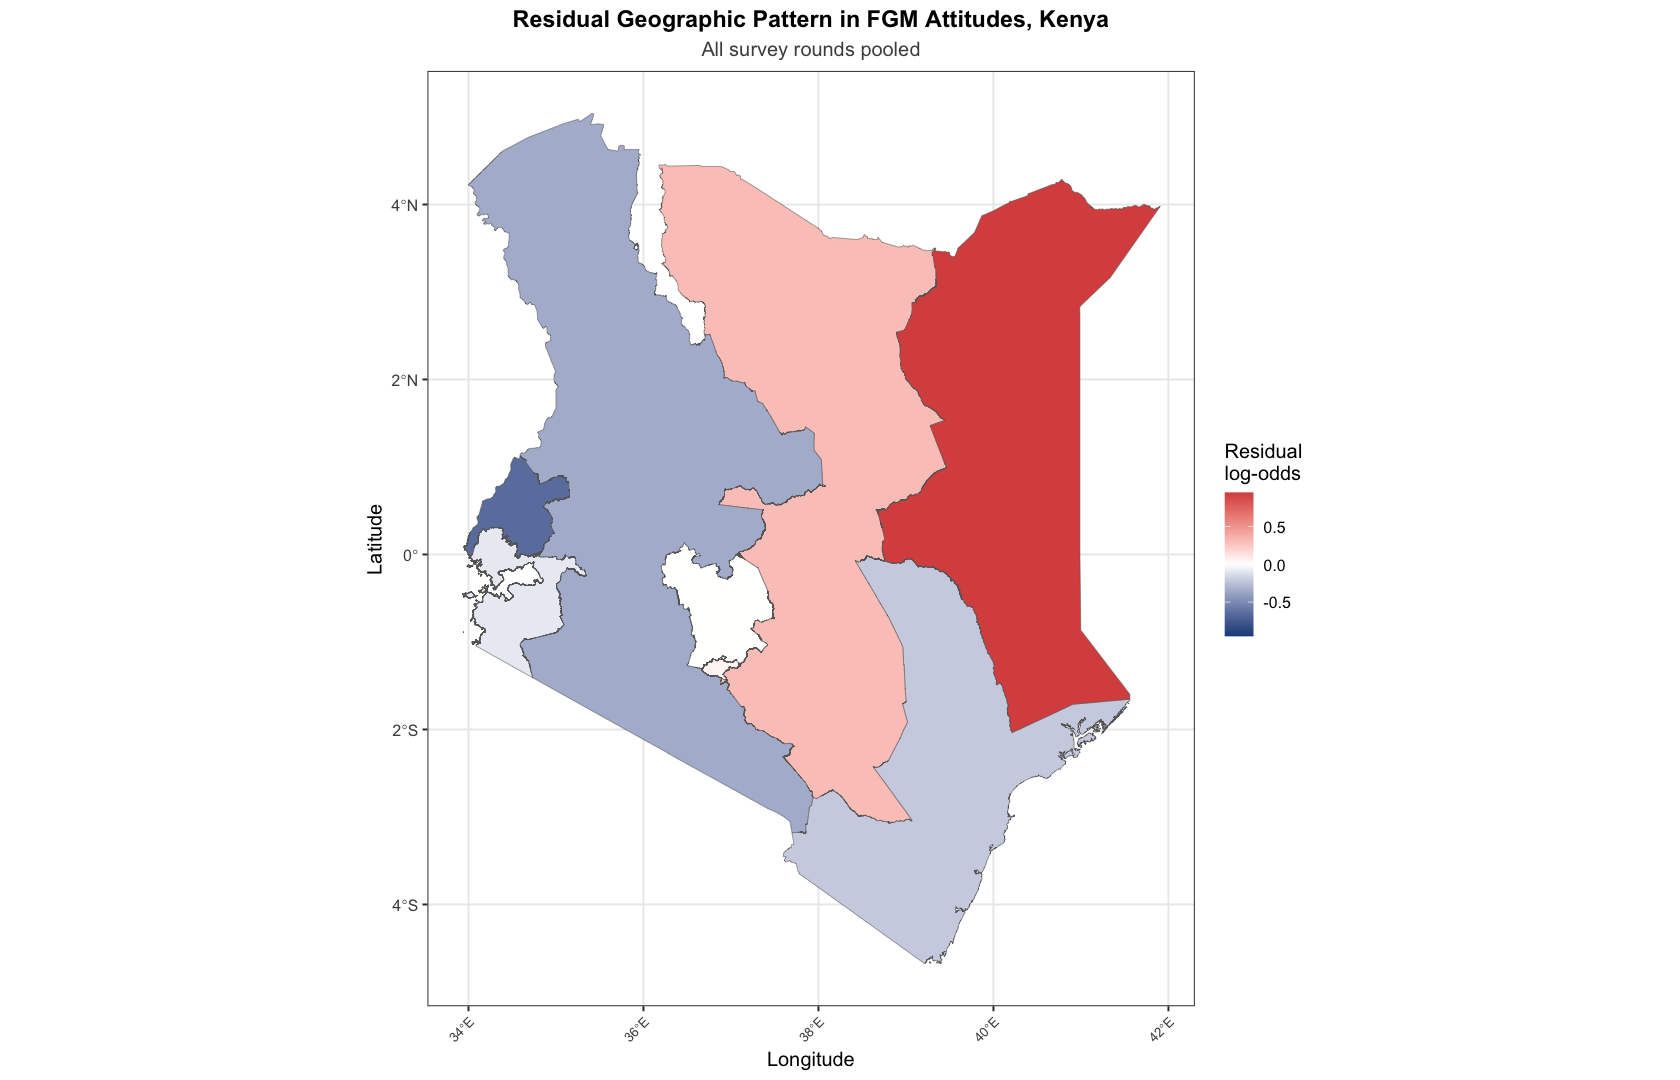

In [27]:
attitude_residual_map <- residual_map(adjusted_model$residual, paste("Residual Geographic Pattern in FGM Attitudes,", country_name),
                                      "All survey rounds pooled")
print(attitude_residual_map)
ggplot2::ggsave(file.path(dirs$maps, paste0(country_iso3, "_attitude_residual_map.png")), attitude_residual_map,
                width = 9, height = 8, dpi = 300, bg = "white")

## 13. Validation and comparison

states_compared,correlation_direct_adjusted,mean_absolute_difference,maximum_absolute_difference
<dbl>,<dbl>,<dbl>,<dbl>
8,1,0.002,0.01


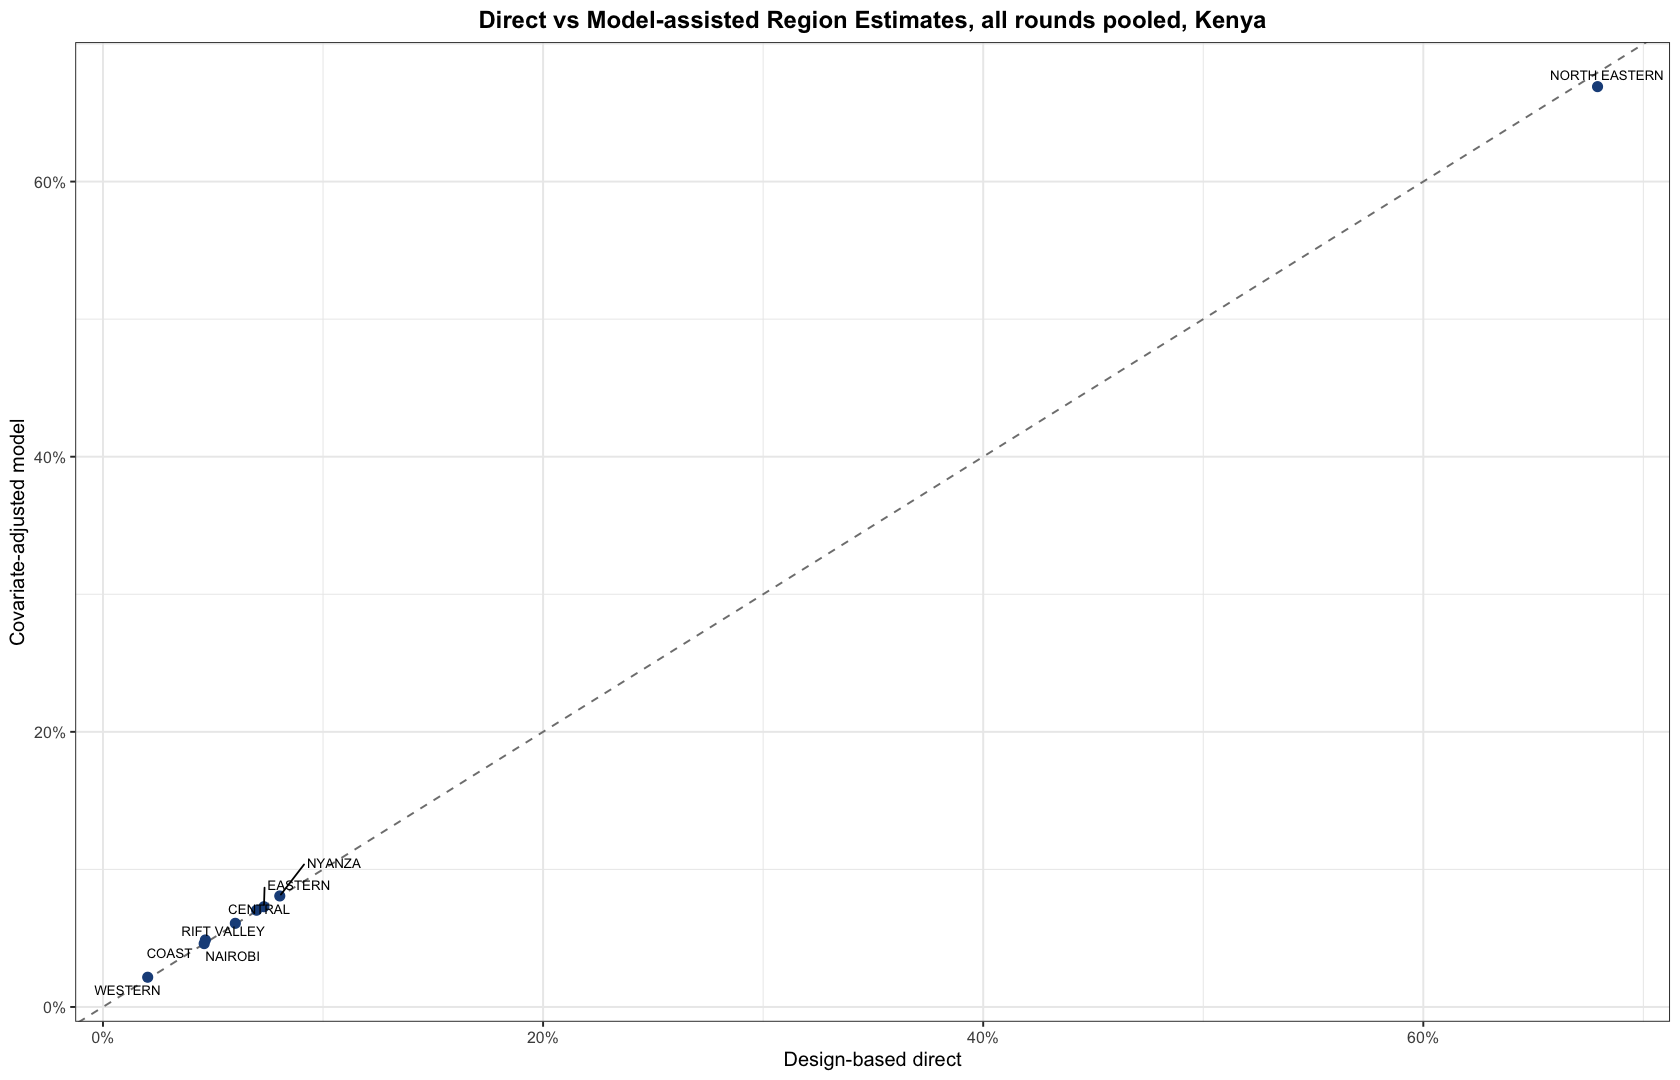

In [28]:
validation_metrics <- adjusted_state |>
  dplyr::summarise(states_compared = sum(stats::complete.cases(direct_support, adjusted_support)),
                   correlation_direct_adjusted = stats::cor(direct_support, adjusted_support, use = "complete.obs"),
                   mean_absolute_difference = mean(abs(adjusted_support - direct_support), na.rm = TRUE),
                   maximum_absolute_difference = max(abs(adjusted_support - direct_support), na.rm = TRUE))
readr::write_csv(validation_metrics, file.path(dirs$validation, paste0(country_iso3, "_attitude_validation_metrics.csv")))
IRdisplay::display(as.data.frame(validation_metrics |> dplyr::mutate(dplyr::across(where(is.numeric), ~ round(.x, 3)))))
validation_plot <- ggplot2::ggplot(adjusted_state, ggplot2::aes(direct_support, adjusted_support)) +
  ggplot2::geom_abline(slope = 1, intercept = 0, linetype = "dashed", color = "grey50") +
  ggplot2::geom_point(color = "#1D4E89", size = 2.4) +
  ggrepel::geom_text_repel(ggplot2::aes(label = region), size = 2.8, seed = 1, max.overlaps = 15) +
  ggplot2::scale_x_continuous(labels = scales::percent_format(accuracy = 1)) +
  ggplot2::scale_y_continuous(labels = scales::percent_format(accuracy = 1)) +
  ggplot2::labs(title = paste("Direct vs Model-assisted Region Estimates, all rounds pooled,", country_name),
                x = "Design-based direct", y = "Covariate-adjusted model") +
  ggplot2::theme_bw(base_size = 12) + ggplot2::theme(plot.title = ggplot2::element_text(face = "bold", hjust = 0.5))
print(validation_plot)
ggplot2::ggsave(file.path(dirs$validation, paste0(country_iso3, "_attitude_validation.png")), validation_plot,
                width = 9, height = 8, dpi = 300, bg = "white")

## 14. National trend across survey rounds

Support for continuation among men who know of FGM, by survey year: design-based
estimates and the pooled model's estimates for each round.

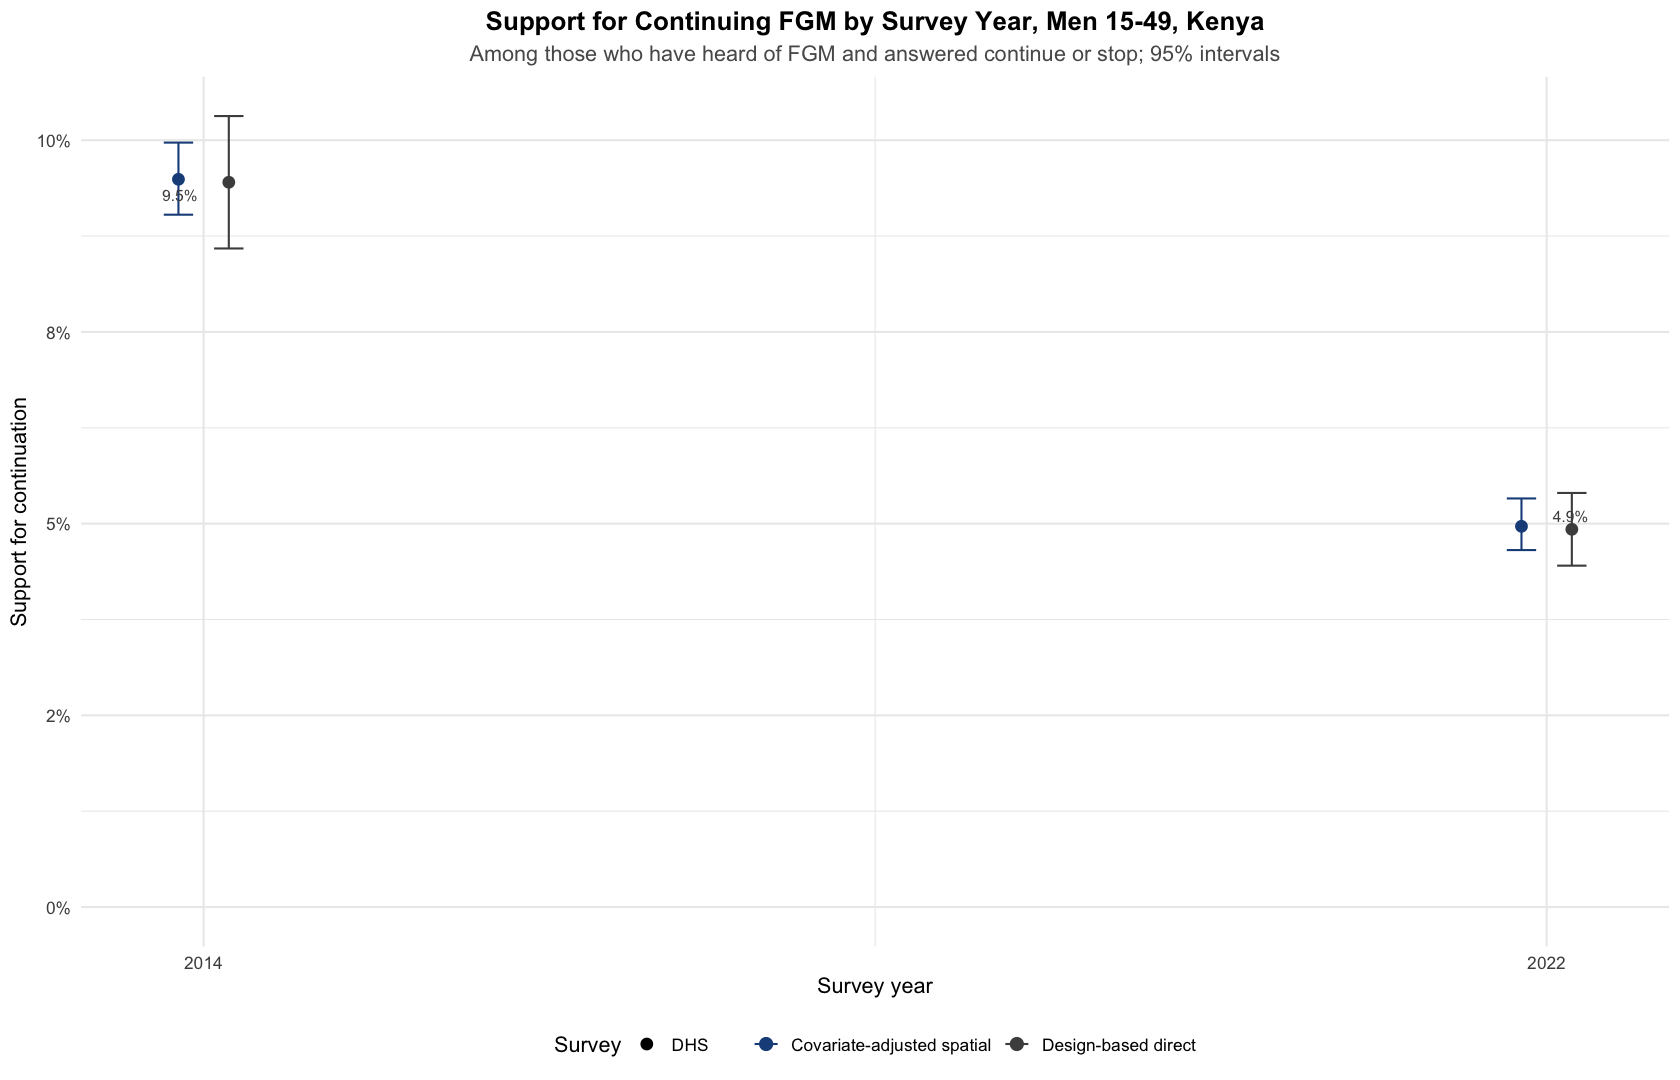

In [29]:
trend_data <- national_comparison |>
  dplyr::left_join(survey_years |> dplyr::mutate(survey_id = as.character(survey_id)), by = "survey_id") |>
  dplyr::filter(method %in% c("Design-based direct", "Covariate-adjusted spatial"))
readr::write_csv(trend_data, file.path(dirs$trends, paste0(country_iso3, "_attitude_national_trend.csv")))
trend_plot <- ggplot2::ggplot(trend_data, ggplot2::aes(round_year, estimate, color = method, shape = survey_type)) +
  ggplot2::geom_errorbar(ggplot2::aes(ymin = lower_ci, ymax = upper_ci), width = 0.35, position = ggplot2::position_dodge(0.6)) +
  ggplot2::geom_point(size = 3.2, position = ggplot2::position_dodge(0.6)) +
  ggrepel::geom_text_repel(data = trend_data |> dplyr::filter(method == "Design-based direct"),
                           ggplot2::aes(label = scales::percent(estimate, accuracy = 0.1)), size = 3.3, seed = 1, show.legend = FALSE) +
  ggplot2::scale_color_manual(values = c("Design-based direct" = "grey30", "Covariate-adjusted spatial" = "#1D4E89")) +
  ggplot2::scale_x_continuous(breaks = sort(unique(trend_data$round_year))) +
  ggplot2::scale_y_continuous(labels = scales::percent_format(accuracy = 1), limits = c(0, NA)) +
  ggplot2::labs(title = paste("Support for Continuing FGM by Survey Year, Men 15-49,", country_name),
                subtitle = "Among those who have heard of FGM and answered continue or stop; 95% intervals",
                x = "Survey year", y = "Support for continuation", color = NULL, shape = "Survey") +
  ggplot2::theme_minimal(base_size = 13) +
  ggplot2::theme(plot.title = ggplot2::element_text(face = "bold", hjust = 0.5),
                 plot.subtitle = ggplot2::element_text(hjust = 0.5, color = "grey35"), legend.position = "bottom")
print(trend_plot)
ggplot2::ggsave(file.path(dirs$trends, paste0(country_iso3, "_attitude_national_trend.png")), trend_plot, width = 11, height = 7, dpi = 300, bg = "white")

## 15. Men compared with women

Pooled region estimates for men and women side by side (each pooled over the rounds that
asked them), and, for each round that surveyed both sexes, a design-based test of the
national men–women difference in one stacked design (each sex keeps its own weights; both
share the DHS clusters and strata).

survey_id,men,women,difference,se,lower_ci,upper_ci,p_value
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
DHS 2014,9.5,6.3,3.2,0.004336054,2.3,4.0,3.68e-13
DHS 2022,4.9,4.4,0.5,0.003345944,-0.1,1.2,1.02e-01


Regions compared: 8 | correlation men vs women: 0.99 | regions where men are higher: 2 


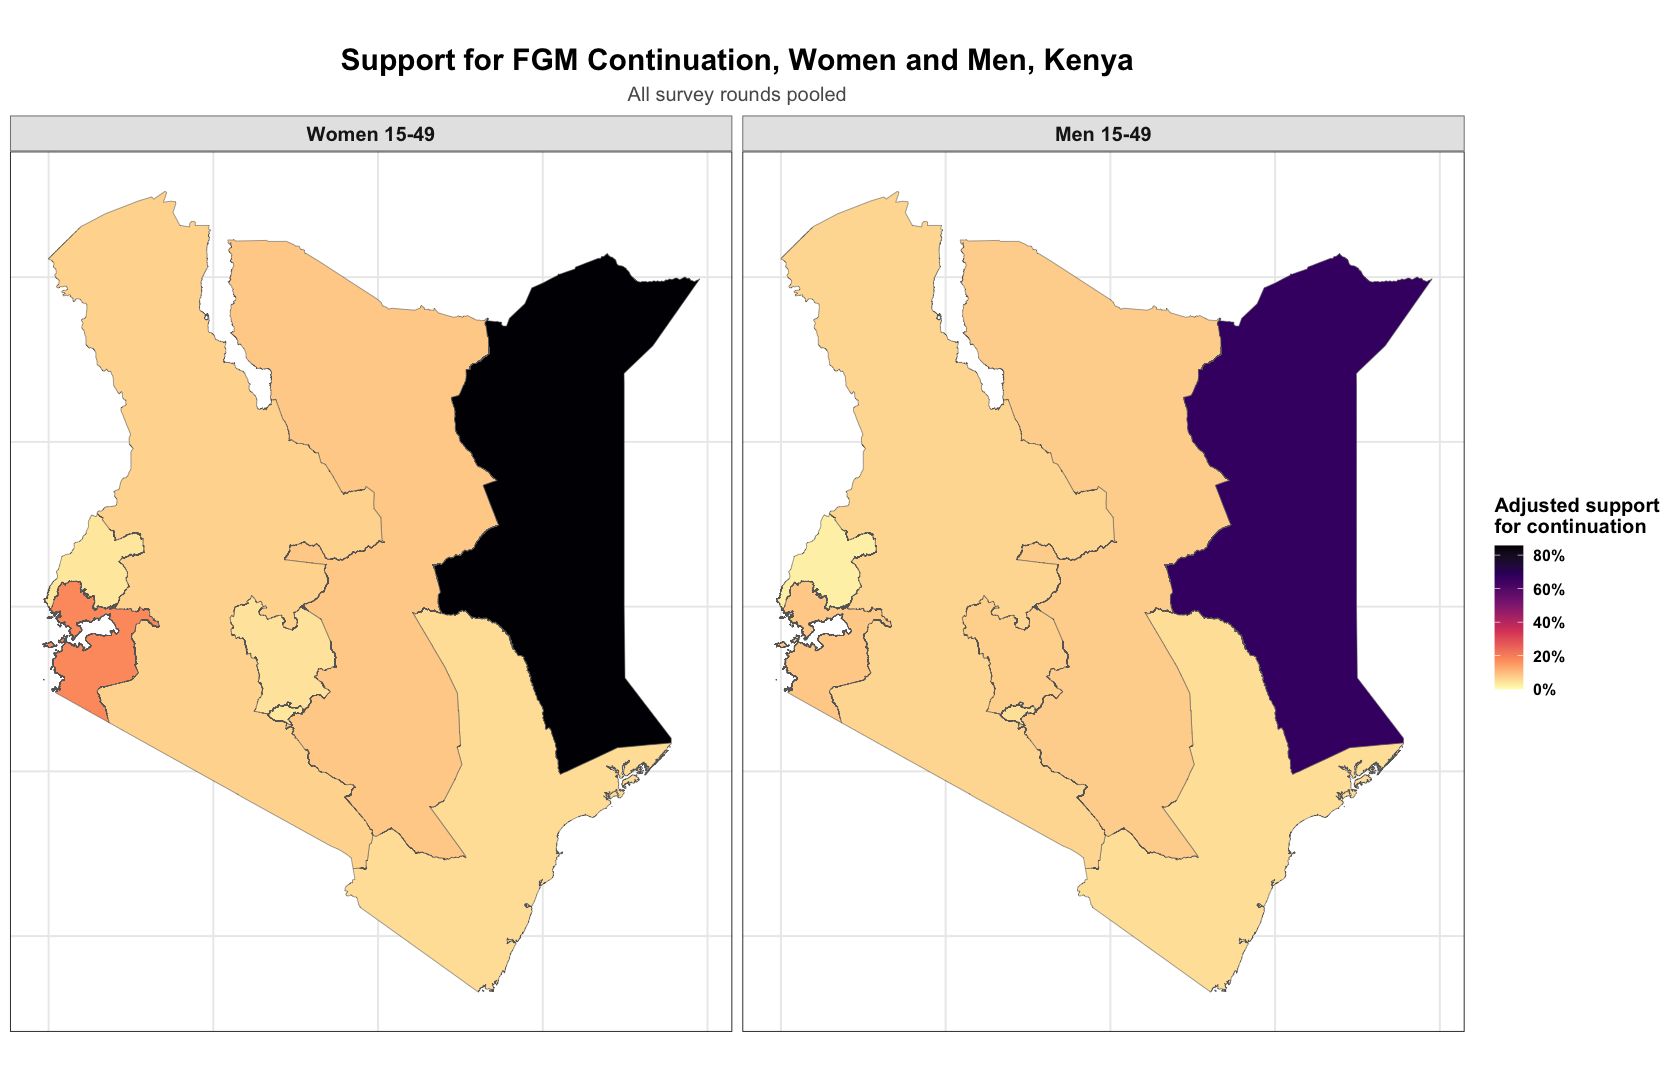

In [30]:
women_attitude <- readRDS(file.path(analysis_dir, paste0(country_iso3, "_attitude_women.rds")))
women_state_path <- file.path(project_root, "03_Outputs", country_iso3, "Attitude_Women", "03_Model_Estimates",
                              paste0(country_iso3, "_attitude_covariate_adjusted_by_region.csv"))
if (!file.exists(women_state_path)) stop("Run Part A (women) first: ", women_state_path)

shared_rounds <- intersect(levels(attitude_all$survey_id), unique(women_attitude$survey_id))
men_vs_women <- purrr::map_dfr(shared_rounds, function(r) {
  stacked <- dplyr::bind_rows(
    women_attitude |> dplyr::filter(survey_id == r) |> dplyr::transmute(sex = "Women", cluster, strata, weight, supports_continuation),
    attitude_all |> dplyr::filter(survey_id == r) |> dplyr::transmute(sex = "Men", cluster, strata, weight, supports_continuation))
  by_sex <- survey::svyby(~supports_continuation, ~sex, design_for(stacked), survey::svymean, covmat = TRUE)
  diff <- survey::svycontrast(by_sex, c(Men = 1, Women = -1))
  tibble::tibble(survey_id = r, men = as.numeric(stats::coef(by_sex)["Men"]), women = as.numeric(stats::coef(by_sex)["Women"]),
                 difference = as.numeric(stats::coef(diff)), se = as.numeric(survey::SE(diff))) |>
    dplyr::mutate(lower_ci = difference - 1.96 * se, upper_ci = difference + 1.96 * se, p_value = 2 * stats::pnorm(-abs(difference / se)))
})
readr::write_csv(men_vs_women, file.path(dirs$comparison, paste0(country_iso3, "_attitude_national_men_vs_women_by_round.csv")))
IRdisplay::display(as.data.frame(men_vs_women |> dplyr::mutate(dplyr::across(c(men, women, difference, lower_ci, upper_ci), ~ round(100 * .x, 1)),
                                                               p_value = signif(p_value, 3))))

women_state <- readr::read_csv(women_state_path, show_col_types = FALSE)
state_by_sex <- dplyr::bind_rows(
  women_state |> dplyr::transmute(region, sex = "Women 15-49", adjusted_support),
  adjusted_state |> dplyr::transmute(region, sex = "Men 15-49", adjusted_support)) |>
  dplyr::mutate(sex = factor(sex, levels = c("Women 15-49", "Men 15-49")))
state_wide <- state_by_sex |> tidyr::pivot_wider(names_from = sex, values_from = adjusted_support) |>
  dplyr::mutate(men_minus_women = `Men 15-49` - `Women 15-49`) |> dplyr::arrange(dplyr::desc(men_minus_women))
readr::write_csv(state_wide, file.path(dirs$comparison, paste0(country_iso3, "_attitude_region_men_vs_women.csv")))
cat("Regions compared:", nrow(state_wide), "| correlation men vs women:",
    round(stats::cor(state_wide$`Men 15-49`, state_wide$`Women 15-49`), 2),
    "| regions where men are higher:", sum(state_wide$men_minus_women > 0), "\n")

men_women_map <- ggplot2::ggplot(boundaries |> dplyr::mutate(region = region_keys) |>
    dplyr::left_join(state_by_sex, by = "region", relationship = "one-to-many")) +
  ggplot2::geom_sf(ggplot2::aes(fill = adjusted_support), color = "grey40", linewidth = 0.15) +
  ggplot2::facet_wrap(~sex, ncol = 2) +
  ggplot2::scale_fill_viridis_c(name = "Adjusted support\nfor continuation", option = "magma", direction = -1,
                                labels = scales::percent_format(accuracy = 1), limits = c(0, max(state_by_sex$adjusted_support, na.rm = TRUE)),
                                oob = scales::squish, na.value = "grey90") +
  ggplot2::labs(title = paste("Support for FGM Continuation, Women and Men,", country_name),
                subtitle = "All survey rounds pooled", x = NULL, y = NULL) +
  ggplot2::theme_bw(base_size = 12) +
  ggplot2::theme(text = ggplot2::element_text(face = "bold"), plot.title = ggplot2::element_text(size = 18, hjust = 0.5),
                 plot.subtitle = ggplot2::element_text(hjust = 0.5, color = "grey35", face = "plain"),
                 strip.text = ggplot2::element_text(size = 12), strip.background = ggplot2::element_rect(fill = "grey90", color = "grey50"),
                 axis.text = ggplot2::element_blank(), axis.ticks = ggplot2::element_blank())
print(men_women_map)
ggplot2::ggsave(file.path(dirs$comparison, paste0(country_iso3, "_attitude_map_men_vs_women.png")), men_women_map,
                width = 15, height = 8, dpi = 300, bg = "white")

## Interpretation and limitations

- The design-based national and region estimates are the survey-design benchmark.
- Models pool all rounds with normalized survey weights in a pseudo-likelihood and a
  survey-round term; their intervals are pseudo-posterior, not fully design-based. Pooled
  provincial estimates describe 1998–2022 as a whole; cohort maps and the trend show change.
- Estimates apply to men aged 15–49 who have heard of FGM and gave a continue/stop
  answer.
- Predictors a round does not collect (wealth in DHS 1998) are kept as an "unknown" category
  in the pooled model.
- DHS 1998 offered only "continue", "discontinue" and "don't know", with no "depends" option, so
  some respondents who would otherwise have said "depends" chose one of the two answers.
- Regions are the 8 former provinces; DHS 2022 counties are mapped to their province.
- Random-forest importance is descriptive and ranks predictors without implying causality.

In [31]:
cat("Attitude analysis completed. Selected predictors:", paste(selected_predictors, collapse = ", "), "\n")
cat("All outputs saved to:", normalizePath(output_dir), "\n")

Attitude analysis completed. Selected predictors: age, ethnicity, region, religion, education, wealth, urban_rural 


All outputs saved to: /Users/jkakai/Desktop/Main/Melaningod/UNFPA/Root/Working Folder/Final FGM Results/Kenya/V2/03_Outputs/KEN/Attitude_Men 


# Part C — Trends in support for continuation, women and men

Design-based national estimates by survey round, with 95% confidence intervals, among
respondents who have heard of FGM and answered "continue" or "stop". Men were asked only in
DHS 2014 and 2022.

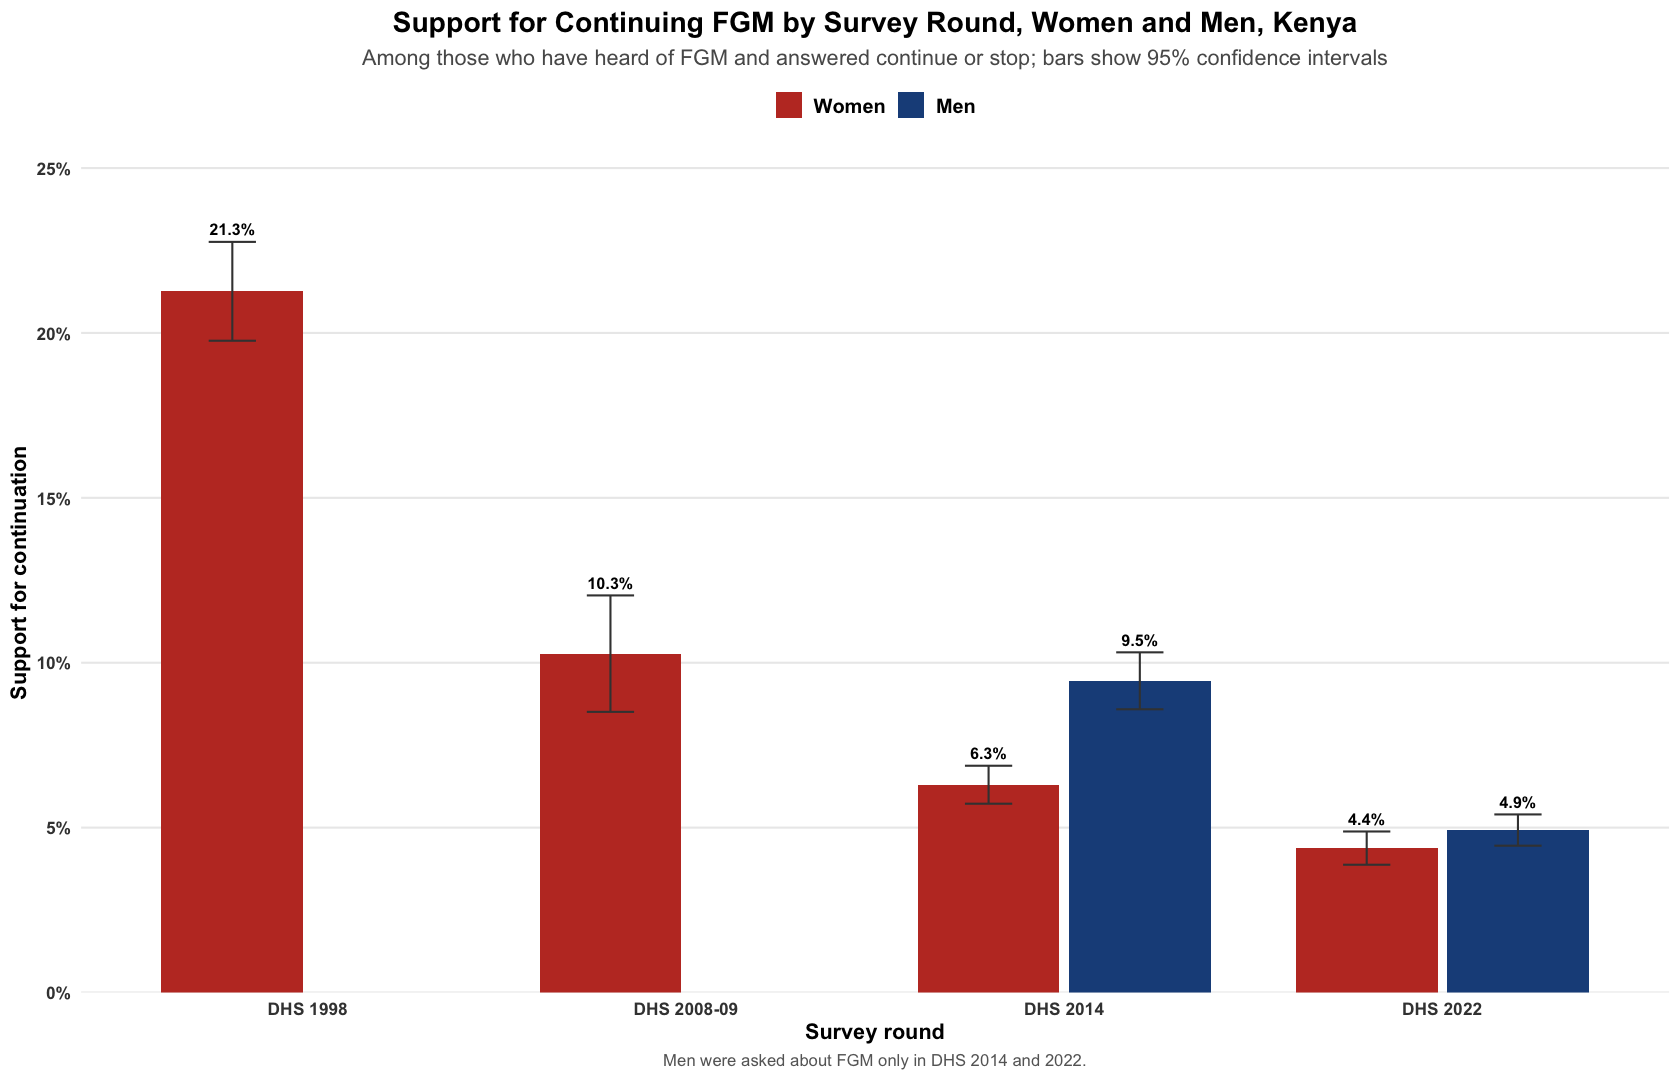

In [32]:
trend_dir <- file.path(project_root, "03_Outputs", country_iso3, "Attitude_Women_and_Men")
dir.create(trend_dir, recursive = TRUE, showWarnings = FALSE)
round_levels <- c("DHS 1998", "DHS 2008", "DHS 2014", "DHS 2022")
round_labels <- sub("DHS 2008", "DHS 2008-09", round_levels)
read_direct <- function(folder, sex) {
  readr::read_csv(file.path(project_root, "03_Outputs", country_iso3, folder, "02_Direct_Estimates",
                            paste0(country_iso3, "_attitude_direct_national_by_round.csv")), show_col_types = FALSE) |>
    dplyr::mutate(sex = sex)
}
attitude_trend <- dplyr::bind_rows(read_direct("Attitude_Women", "Women"), read_direct("Attitude_Men", "Men")) |>
  dplyr::mutate(survey_id = factor(survey_id, levels = round_levels, labels = round_labels),
                sex = factor(sex, levels = c("Women", "Men")))
readr::write_csv(attitude_trend, file.path(trend_dir, paste0(country_iso3, "_attitude_trend_women_men.csv")))

sex_colours <- c(Women = "#C0392B", Men = "#1D4E89")
bar_theme <- ggplot2::theme_minimal(base_size = 13) +
  ggplot2::theme(plot.title = ggplot2::element_text(face = "bold", size = 17, hjust = 0.5),
                 plot.subtitle = ggplot2::element_text(hjust = 0.5, color = "grey35"),
                 plot.caption = ggplot2::element_text(color = "grey40", size = 10, hjust = 0.5),
                 axis.title = ggplot2::element_text(face = "bold"),
                 axis.text = ggplot2::element_text(face = "bold", color = "grey25"),
                 panel.grid.major.x = ggplot2::element_blank(), panel.grid.minor = ggplot2::element_blank(),
                 legend.position = "top", legend.title = ggplot2::element_blank(),
                 legend.text = ggplot2::element_text(face = "bold", size = 12))

trend_bars <- ggplot2::ggplot(attitude_trend, ggplot2::aes(survey_id, estimate, fill = sex)) +
  ggplot2::geom_col(position = ggplot2::position_dodge(width = 0.8, preserve = "single"), width = 0.75) +
  ggplot2::geom_errorbar(ggplot2::aes(ymin = lower_ci, ymax = upper_ci),
                         position = ggplot2::position_dodge(width = 0.8, preserve = "single"), width = 0.25, color = "grey25") +
  ggplot2::geom_text(ggplot2::aes(y = upper_ci, label = scales::percent(estimate, accuracy = 0.1)),
                     position = ggplot2::position_dodge(width = 0.8, preserve = "single"), vjust = -0.6, size = 3.4, fontface = "bold") +
  ggplot2::scale_fill_manual(values = sex_colours) +
  ggplot2::scale_y_continuous(labels = scales::percent_format(accuracy = 1), limits = c(0, NA),
                              expand = ggplot2::expansion(mult = c(0, 0.12))) +
  ggplot2::labs(title = paste("Support for Continuing FGM by Survey Round, Women and Men,", country_name),
                subtitle = "Among those who have heard of FGM and answered continue or stop; bars show 95% confidence intervals",
                caption = "Men were asked about FGM only in DHS 2014 and 2022.",
                x = "Survey round", y = "Support for continuation") +
  bar_theme
print(trend_bars)
ggplot2::ggsave(file.path(trend_dir, paste0(country_iso3, "_attitude_trend_bars_women_men.png")), trend_bars,
                width = 13, height = 7.5, dpi = 300, bg = "white")

sex,survey_id,estimate,lower_ci,upper_ci,n
<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>
Women,DHS 1998,21.3,19.8,22.8,7314
Women,DHS 2008-09,10.3,8.5,12.0,7609
Women,DHS 2014,6.3,5.7,6.9,14073
Women,DHS 2022,4.4,3.9,4.9,15890
Men,DHS 2014,9.5,8.6,10.3,11507
Men,DHS 2022,4.9,4.5,5.4,12878


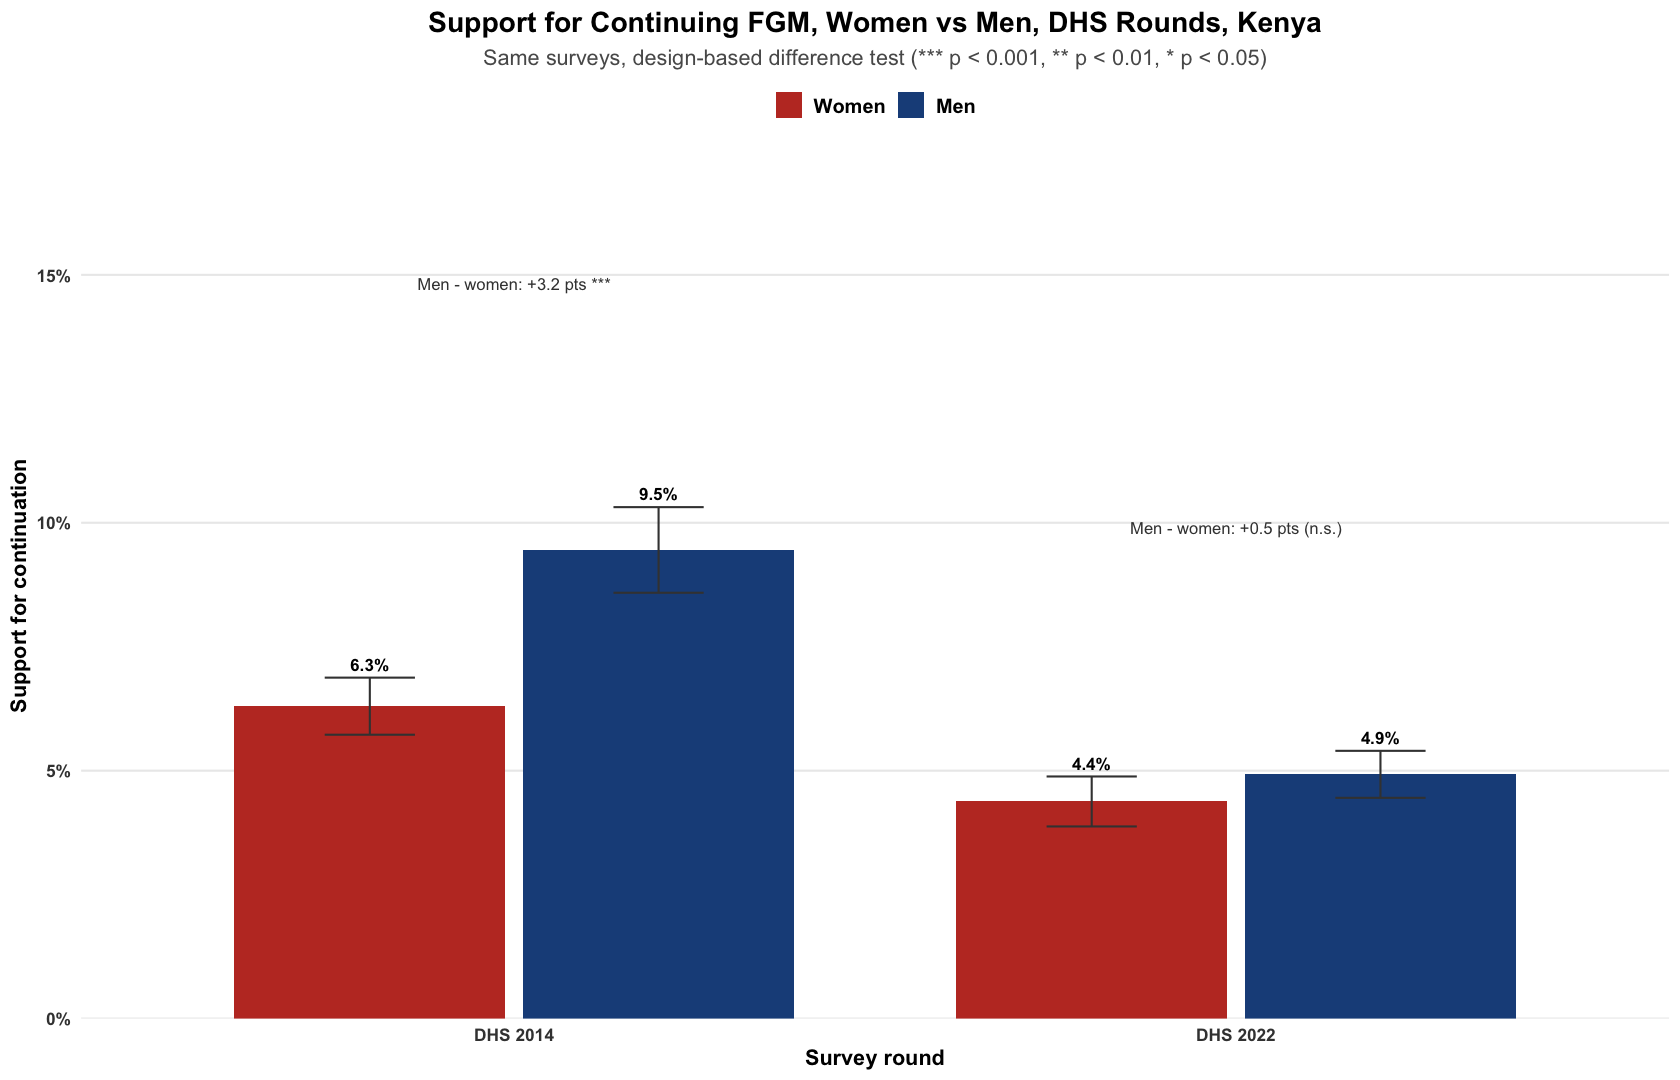

In [33]:
men_vs_women <- readr::read_csv(file.path(project_root, "03_Outputs", country_iso3, "Attitude_Men", "07_Men_vs_Women",
                                          paste0(country_iso3, "_attitude_national_men_vs_women_by_round.csv")), show_col_types = FALSE)
# Use the same display labels as the trend chart ("DHS 2008" is shown as "DHS 2008-09").
men_vs_women <- men_vs_women |> dplyr::mutate(survey_id = round_labels[match(survey_id, round_levels)])
shared <- attitude_trend |> dplyr::filter(as.character(survey_id) %in% men_vs_women$survey_id) |>
  dplyr::mutate(survey_id = droplevels(survey_id))
significance <- men_vs_women |>
  dplyr::mutate(label = paste0(ifelse(difference > 0, "+", ""), round(100 * difference, 1), " pts",
                               dplyr::case_when(p_value < 0.001 ~ " ***", p_value < 0.01 ~ " **", p_value < 0.05 ~ " *", TRUE ~ " (n.s.)")),
                survey_id = factor(survey_id, levels = levels(shared$survey_id))) |>
  dplyr::left_join(shared |> dplyr::group_by(survey_id) |> dplyr::summarise(top = max(upper_ci), .groups = "drop"), by = "survey_id")

dhs_bars <- ggplot2::ggplot(shared, ggplot2::aes(survey_id, estimate, fill = sex)) +
  ggplot2::geom_col(position = ggplot2::position_dodge(width = 0.8), width = 0.75) +
  ggplot2::geom_errorbar(ggplot2::aes(ymin = lower_ci, ymax = upper_ci), position = ggplot2::position_dodge(width = 0.8),
                         width = 0.25, color = "grey25") +
  ggplot2::geom_text(ggplot2::aes(y = upper_ci, label = scales::percent(estimate, accuracy = 0.1)),
                     position = ggplot2::position_dodge(width = 0.8), vjust = -0.6, size = 3.6, fontface = "bold") +
  ggplot2::geom_text(data = significance, ggplot2::aes(x = survey_id, y = top + 0.045, label = paste("Men - women:", label)),
                     inherit.aes = FALSE, size = 3.5, color = "grey25") +
  ggplot2::scale_fill_manual(values = sex_colours) +
  ggplot2::scale_y_continuous(labels = scales::percent_format(accuracy = 1), limits = c(0, NA),
                              expand = ggplot2::expansion(mult = c(0, 0.18))) +
  ggplot2::labs(title = paste("Support for Continuing FGM, Women vs Men, DHS Rounds,", country_name),
                subtitle = "Same surveys, design-based difference test (*** p < 0.001, ** p < 0.01, * p < 0.05)",
                x = "Survey round", y = "Support for continuation") +
  bar_theme
print(dhs_bars)
ggplot2::ggsave(file.path(trend_dir, paste0(country_iso3, "_attitude_women_vs_men_dhs_bars.png")), dhs_bars,
                width = 11, height = 7, dpi = 300, bg = "white")
IRdisplay::display(as.data.frame(attitude_trend |> dplyr::select(sex, survey_id, estimate, lower_ci, upper_ci, n) |>
  dplyr::mutate(dplyr::across(c(estimate, lower_ci, upper_ci), ~ round(100 * .x, 1))) |> dplyr::arrange(sex, survey_id)))

# Part D — Subnational MICS comparison and county estimates

**D.1 MICS.** Women's support for continuing FGM in each MICS area against DHS for the same area
(as in the prevalence notebook, section 8A). **D.2 Counties.** BYM2-smoothed county support from
DHS 2014 and 2022 for women, and pooled 2014 and 2022 for men (smaller samples).

In [34]:
source(file.path(project_root, "00_Pipeline", "mics_core.R"))
source(file.path(project_root, "00_Pipeline", "county_core.R"))
options(survey.lonely.psu = "adjust")
pct1 <- function(x) round(100 * x, 1)
harmonized_path <- file.path(project_root, "02_Data", "processed", country_iso3, "harmonized")
h_women <- readRDS(file.path(harmonized_path, paste0(country_iso3, "_women_all_rounds.rds"))) |>
  dplyr::mutate(fgm_heard = as.numeric(fgm_heard))
mics_women <- readRDS(file.path(harmonized_path, paste0(country_iso3, "_mics_subnational_women.rds")))

att_out <- file.path(project_root, "03_Outputs", country_iso3, "Attitude_Women_and_Men", "MICS_and_County")
dir.create(att_out, recursive = TRUE, showWarnings = FALSE)
mics_att <- mics_vs_dhs(mics_women, h_women, "supports_continuation")
mics_att_table <- mics_att |> dplyr::transmute(comparison, area, source, support = pct1(estimate), lower_ci = pct1(lower_ci),
                                               upper_ci = pct1(upper_ci), n)
readr::write_csv(mics_att_table, file.path(att_out, paste0(country_iso3, "_mics_support_by_source.csv")))
IRdisplay::display(as.data.frame(mics_att_table))

comparison,area,source,support,lower_ci,upper_ci,n
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<int>
MICS 2009 Mombasa informal settlements,MOMBASA,MICS 2009 Mombasa informal settlements,4.0,2.3,5.7,720
MICS 2009 Mombasa informal settlements,MOMBASA,DHS 2014,2.0,0.3,3.6,270
MICS 2011 Nyanza,NYANZA,MICS 2011 Nyanza,22.3,20.2,24.4,4293
MICS 2011 Nyanza,NYANZA,DHS 2008,20.1,13.3,26.9,1059
MICS 2011 Nyanza,NYANZA,DHS 2014,8.9,7.3,10.6,1834
MICS 2013-14 Bungoma,BUNGOMA,MICS 2013-14 Bungoma,1.8,0.8,2.9,1034
MICS 2013-14 Bungoma,BUNGOMA,DHS 2014,2.1,0.7,3.6,368
MICS 2013-14 Kakamega,KAKAMEGA,MICS 2013-14 Kakamega,3.0,1.7,4.2,819
MICS 2013-14 Kakamega,KAKAMEGA,DHS 2014,1.3,0.2,2.4,335


county,direct,se,n,smoothed,lower_ci,upper_ci,survey_id
<chr>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<chr>
MANDERA,97.8,0.01313098,259,97.3,0.9204130,0.9915153,DHS 2014
GARISSA,88.9,0.02815919,271,87.0,0.7957615,0.9206027,DHS 2014
WAJIR,84.2,0.03321926,239,84.0,0.7653245,0.8945319,DHS 2014
MARSABIT,73.4,0.04093589,266,72.9,0.6424792,0.8015301,DHS 2014
SAMBURU,51.4,0.05217197,251,49.3,0.3945636,0.5925890,DHS 2014
ISIOLO,39.5,0.05660449,283,39.5,0.2941651,0.5047522,DHS 2014
MANDERA,90.8,0.02629110,396,90.5,0.8386569,0.9461814,DHS 2022
WAJIR,81.9,0.02616704,408,81.2,0.7539008,0.8583122,DHS 2022
GARISSA,71.4,0.06255818,361,67.5,0.5391626,0.7868026,DHS 2022


county,direct,se,n,smoothed,lower_ci,upper_ci,survey_id
<chr>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<chr>
MANDERA,87.3,0.02194270,449,87.0,0.8198958,0.9077474,DHS 2014 and 2022 pooled
WAJIR,66.6,0.03123199,483,66.1,0.5976383,0.7184106,DHS 2014 and 2022 pooled
GARISSA,56.6,0.08602968,478,50.0,0.3502580,0.6515641,DHS 2014 and 2022 pooled
MARSABIT,33.8,0.03895289,386,34.0,0.2698393,0.4188473,DHS 2014 and 2022 pooled
SAMBURU,35.1,0.04549710,328,32.4,0.2474886,0.4112866,DHS 2014 and 2022 pooled
ISIOLO,32.6,0.04487788,434,31.3,0.2383563,0.3995315,DHS 2014 and 2022 pooled


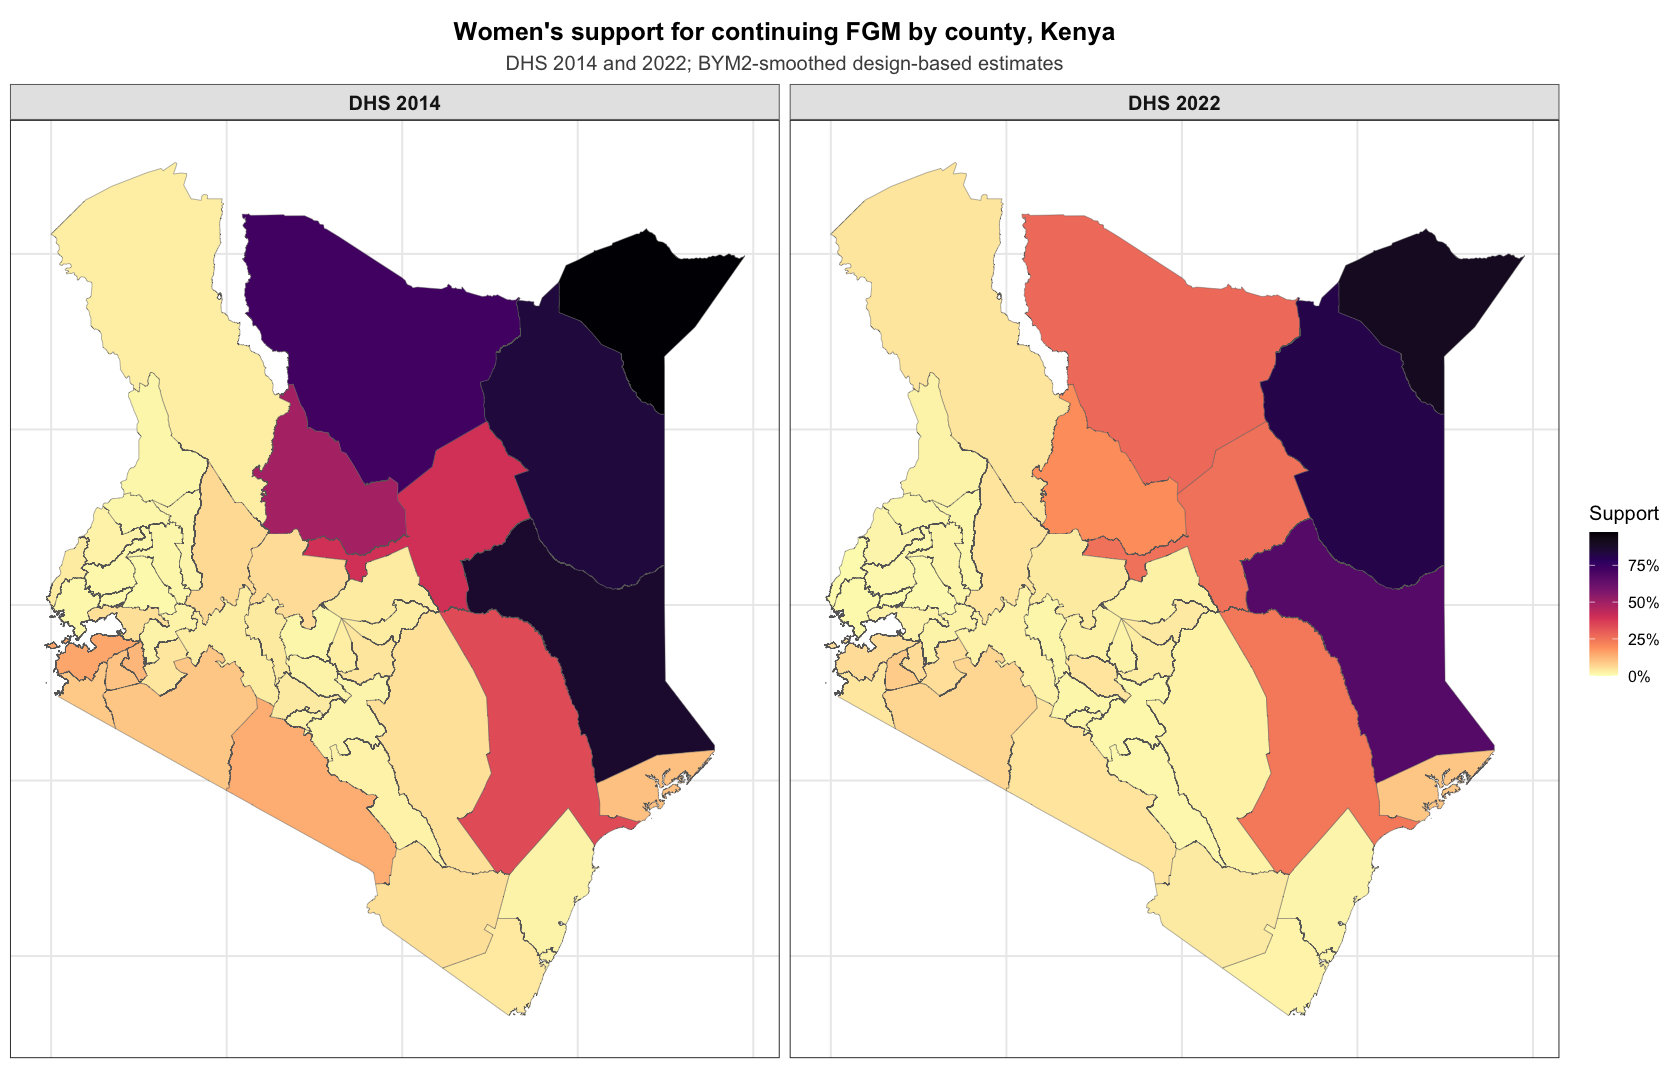

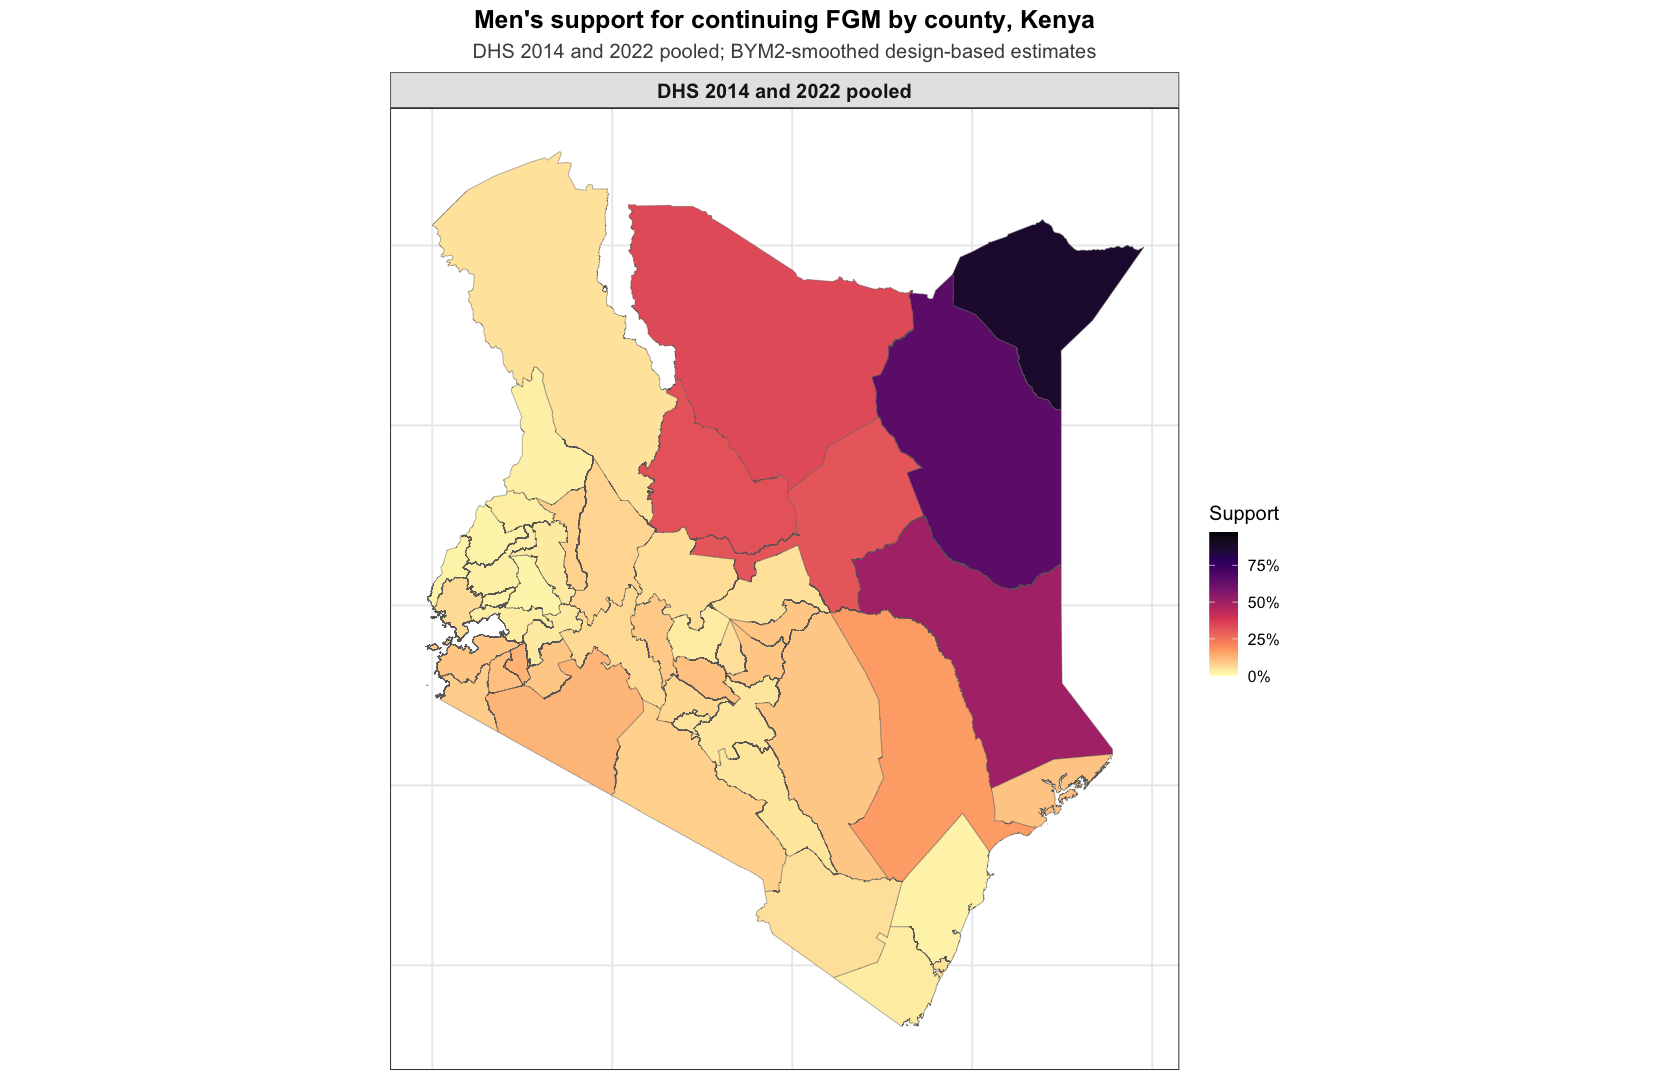

In [35]:
county_b <- county_boundaries(project_root)
h_men <- readRDS(file.path(harmonized_path, paste0(country_iso3, "_men_all_rounds.rds")))
county_support_women <- county_series(h_women, "supports_continuation", c("DHS 2014", "DHS 2022"), county_b)
county_support_men <- county_smooth(county_direct(h_men |> dplyr::filter(survey_id %in% c("DHS 2014", "DHS 2022")),
                                                  "supports_continuation"), county_b) |>
  dplyr::mutate(survey_id = "DHS 2014 and 2022 pooled")
readr::write_csv(county_support_women, file.path(att_out, paste0(country_iso3, "_county_support_women.csv")))
readr::write_csv(county_support_men, file.path(att_out, paste0(country_iso3, "_county_support_men.csv")))
IRdisplay::display(as.data.frame(county_support_women |> dplyr::group_by(survey_id) |> dplyr::slice_max(smoothed, n = 6) |>
  dplyr::mutate(dplyr::across(c(direct, smoothed), pct1))))
IRdisplay::display(as.data.frame(county_support_men |> dplyr::slice_max(smoothed, n = 6) |> dplyr::mutate(dplyr::across(c(direct, smoothed), pct1))))
lims <- c(0, max(c(county_support_women$smoothed, county_support_men$smoothed), na.rm = TRUE))
p_w <- county_map(county_support_women, county_b, "Women's support for continuing FGM by county, Kenya",
                  "DHS 2014 and 2022; BYM2-smoothed design-based estimates", "Support", lims)
p_m <- county_map(county_support_men, county_b, "Men's support for continuing FGM by county, Kenya",
                  "DHS 2014 and 2022 pooled; BYM2-smoothed design-based estimates", "Support", lims)
print(p_w); print(p_m)
ggplot2::ggsave(file.path(att_out, paste0(country_iso3, "_county_support_women.png")), p_w, width = 13, height = 7, dpi = 300, bg = "white")
ggplot2::ggsave(file.path(att_out, paste0(country_iso3, "_county_support_men.png")), p_m, width = 8, height = 7, dpi = 300, bg = "white")

## Results

**1. Support for continuation has fallen.** Among women who have heard of FGM, support fell from
21.3% in DHS 1998 to 10.3% (2008–09), 6.3% (2014) and 4.4% (2022). Among men it fell from 9.5%
(2014) to 4.9% (2022); men were more supportive than women in 2014 (+3.2 points, p < 0.001) but not
in 2022 (+0.5 points, not significant).

**2. North Eastern.** Pooled support is 85.6% among women and 66.9% among men in North Eastern,
against 3–18% among women and 2–8% among men elsewhere (Nyanza women 18.0%). By county (2022),
women's support is highest in Mandera (90.5%), Wajir (81.2%) and Garissa (67.5%).

**3. Who supports continuation.** Women who have not been cut have far lower odds of support
(0.12). Relative to Kalenjin, support is higher among Somali women (7.1) and men (6.7) and Kisii
women (4.2); it is lower with secondary education (women 0.26, men 0.33).

**4. Subnational MICS (Part D).** MICS and DHS support agree in Bungoma, Kakamega and Turkana
(2–6%); in Nyanza support fell from 22.3% (MICS 2011) to 8.9% (DHS 2014).